In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from visualization import (
    plot_cost_function_with_minima, 
    plot_ploidy_optimization,
    plot_ploidy_comparison,  # Add this
    print_overlap_matrix, 
    plot_overlap_matrix_figure,
    plot_uniformity_histograms_nice
)
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

import time

/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
numb = "57"
tumor = "t"+numb

In [3]:
bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt", sep = "\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values
#normal_cells = pd.read_csv(f"../data/{tumor}/normal_cells.txt", header=None, sep="\t")[0].values

In [4]:
bincounts[bincounts["chrom"]=="chr19"]

,chrom,loc.start,loc.end,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,...,TTTTGGAGTTTGCGTCT,TTTTGGATTCCTAGAGA,TTTTGGGAACAATAAGC,TTTTGGGGGTTTTCAGA,TTTTGGGTCTTTAGTCG,TTTTGGGTCTTTCTACT,TTTTGGTAAGCTCAAGT,TTTTGGTGCAGGAATCA,TTTTGGTGCAGGAGAAG,TTTTGGTTTGGAAGTAC
78,chr19,0,56806255,2659444323,2716250578,650,1300,415,1516,988,...,567,1361,692,984,1756,1897,851,1067,308,934
79,chr19,57365282,58522984,2716809605,2717967307,13,35,12,22,14,...,9,43,13,18,27,31,27,17,0,20


In [5]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")
B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t")
C_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t")
D_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t")
equi_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_equi_bins.txt", sep="\t")
#C_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_C_WGS_with_broken_cells.txt", sep="\t")

In [6]:
A_df.head()

,cell,population,normal_population
0,AAAACCAACCTGATAAC,A1,True
1,AAAACCAATTTCAGTAC,A1,True
2,AAAACCAGTGAGTCTAC,A1,True
3,AAAACCATGAGGAGAAG,A1,True
4,AAAACCGAACCCGTACA,A1,True


In [7]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }


A1
A21
A2211
A2212
A2221
A2222


In [8]:
B_dict = {}
for cluster in B_df['population'].unique():
    print(cluster)
    cells_in_cluster = B_df[B_df['population'] == cluster]['cell'].tolist()
    B_dict[cluster] = {
        'cells': cells_in_cluster
    }

B11
B121
B1221
B1222
B2


In [9]:
C_dict = {}
for cluster in C_df['population'].unique():
    print(cluster)
    cells_in_cluster = C_df[C_df['population'] == cluster]['cell'].tolist()
    C_dict[cluster] = {
        'cells': cells_in_cluster
    }

C1
C2111
C2112
C2121
C21221
C21222
C22


In [10]:
D_dict = {}
for cluster in D_df['population'].unique():
    print(cluster)
    cells_in_cluster = D_df[D_df['population'] == cluster]['cell'].tolist()
    D_dict[cluster] = {
        'cells': cells_in_cluster
    }

D1111
D1112
D11211
D11212
D1122
D121
D122
D2


In [11]:
equi_dict = {}
for cluster in equi_df['population'].unique():
    print(cluster)
    cells_in_cluster = equi_df[equi_df['population'] == cluster]['cell'].tolist()
    equi_dict[cluster] = {
        'cells': cells_in_cluster
    }

Pop1111
Pop1112
Pop1121
Pop1122
Pop121
Pop122
Pop2


In [12]:
overlap_df = print_overlap_matrix(A_dict, equi_dict, name1="WGS bins - ", name2="equi-partitioned bins -")


Overlap Matrix (WGS bins -  rows vs equi-partitioned bins - cols):
Pop      Pop1111 Pop1112 Pop1121 Pop1122  Pop121  Pop122    Pop2
A1             0       0       0       2       0       1    1722
A21            0       0       0       0     223     144       2
A2211          2       0       1      53       0       0       0
A2212          0       2      78       1       0       0       0
A2221         13     169       0       1       0       0       0
A2222        115       0       1       3       0       0       0


In [13]:
new_order = []
for col in overlap_df.columns:
    #Find the index of the maximum value in the column
    max_index = overlap_df[col].idxmax()
    if max_index not in new_order:
        new_order.append(max_index)

for row in overlap_df.index:
    if row not in new_order:
        new_order.append(row)
new_order_dict = {k: A_dict[k] for k in new_order}
    

In [14]:
cluster_counts = bincounts[["chrom", "abstart", "abend"]].copy()
for cluster in A_dict.keys():
    cells_in_cluster = A_dict[cluster]['cells']
    cluster_counts[cluster] = bincounts[cells_in_cluster].sum(axis=1)

In [15]:
cluster_counts.to_csv(f"../data/{tumor}/{tumor}_cluster_counts_A_WGS_bins.txt", sep="\t", index=False)


Overlap Matrix (A rows vs B cols):
Pop      Pop1111 Pop1112 Pop1121 Pop1122  Pop121  Pop122    Pop2
A1             0       0       0       2       0       1    1722
A21            0       0       0       0     223     144       2
A2211          2       0       1      53       0       0       0
A2212          0       2      78       1       0       0       0
A2221         13     169       0       1       0       0       0
A2222        115       0       1       3       0       0       0


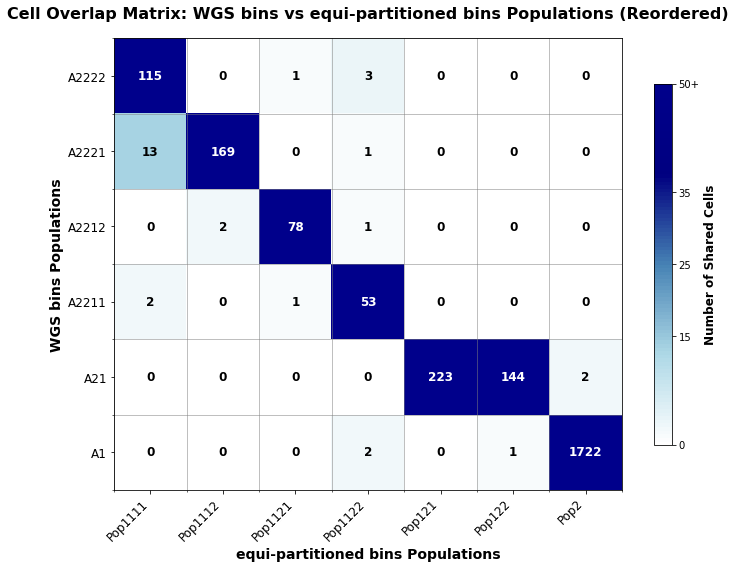

In [16]:
overlap_df = plot_overlap_matrix_figure(A_dict, equi_dict, name1="WGS bins", name2="equi-partitioned bins")


Overlap Matrix (A rows vs B cols):
Pop          B11    B121   B1221   B1222      B2
A1             0       0       0       2    1723
A21          369       0       0       0       0
A2211          0       2       1      53       0
A2212          0       0      81       0       0
A2221          0     181       1       1       0
A2222          0     112       2       5       0


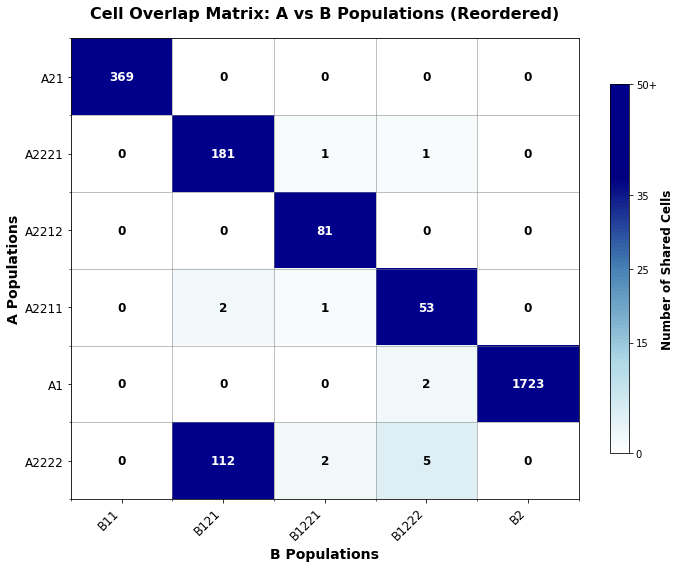

In [17]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="B")


Overlap Matrix (A rows vs B cols):
Pop           C1   C2111   C2112   C2121  C21221  C21222     C22
A1          1725       0       0       0       0       0       0
A21            0       0       0       0       0       0     369
A2211          0       0      53       0       1       2       0
A2212          0      81       0       0       0       0       0
A2221          0       0       0     166       0      17       0
A2222          0       1       1       0      35      82       0


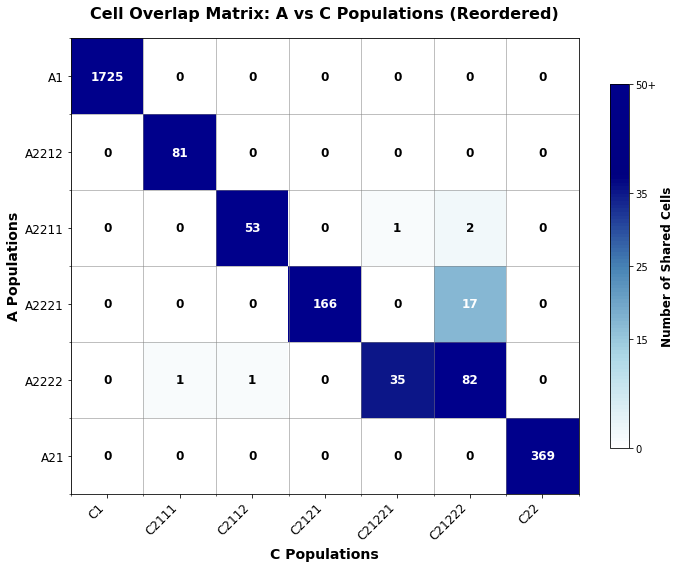

In [18]:
overlap_df = plot_overlap_matrix_figure(A_dict, C_dict, name1="A", name2="C")


Overlap Matrix (A rows vs B cols):
Pop          B11    B121   B1221   B1222      B2
A1             0       0       0       2    1723
A21          369       0       0       0       0
A2211          0       2       1      53       0
A2212          0       0      81       0       0
A2221          0     181       1       1       0
A2222          0     112       2       5       0


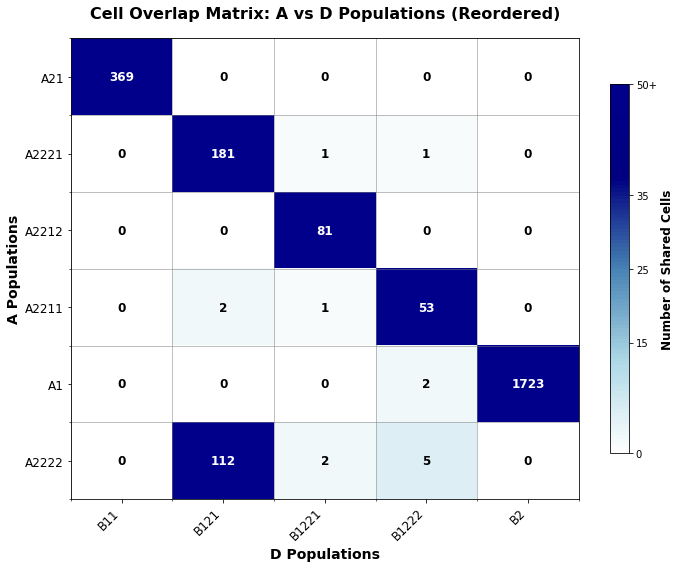

In [19]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="D")

In [20]:
# Prepare the data - create the data DataFrame with segment info
data = bincounts[["chrom","abstart", "abend"]].copy()
data_no_WGS = bincounts_no_WGS[["chrom","abstart", "abend"]].copy()
for cell in cells:
    if cell in bincounts.columns:
        data[cell] = bincounts[cell].values
        data_no_WGS[cell] = bincounts_no_WGS[cell].values
data["lengths"] = data["abend"] - data["abstart"]
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]

# Get just the cell count data for analysis
all_data = data[cells].copy()
all_data_no_WGS = data_no_WGS[cells].copy()

In [21]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)
print("=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)
relative_counts_B = compute_read_counts_relative_to_normal(all_data, B_dict, normal_B)
print("=== Population Set C Analysis ===")
avg_counts_C, ratios_C, normal_C = compute_average_segment_counts(all_data, C_dict, data)
relative_counts_C = compute_read_counts_relative_to_normal(all_data, C_dict, normal_C)
print("=== Population Set D Analysis ===")
avg_counts_D, ratios_D, normal_D = compute_average_segment_counts(all_data, D_dict, data)
relative_counts_D = compute_read_counts_relative_to_normal(all_data, D_dict, normal_D)



=== Population Set A Analysis ===
Normal population identified as: A1
Mean read count ratio for population A1 relative to normal (A1): 1.00
Mean read count ratio for population A21 relative to normal (A1): 1.17
Mean read count ratio for population A2211 relative to normal (A1): 1.35
Mean read count ratio for population A2212 relative to normal (A1): 1.22
Mean read count ratio for population A2221 relative to normal (A1): 1.27
Mean read count ratio for population A2222 relative to normal (A1): 1.26
=== Population Set B Analysis ===
Normal population identified as: B2
Mean read count ratio for population B11 relative to normal (B2): 1.17
Mean read count ratio for population B121 relative to normal (B2): 1.27
Mean read count ratio for population B1221 relative to normal (B2): 1.22
Mean read count ratio for population B1222 relative to normal (B2): 1.32
Mean read count ratio for population B2 relative to normal (B2): 1.00
=== Population Set C Analysis ===
Normal population identified as: C

In [22]:
#Add normal to the A_df population assignments
A_df["normal_population"] = (A_df['population'] == normal_A)
B_df["normal_population"] = (B_df['population'] == normal_B)
C_df["normal_population"] = (C_df['population'] == normal_C)
D_df["normal_population"] = (D_df['population'] == normal_D)

In [23]:
A_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t", index = False)
B_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t", index = False)
C_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t", index = False)
D_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t", index = False)

In [24]:
# A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")
# A_dict = {}
# for cluster in A_df['population'].unique():
#     print(cluster)
#     cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
#     A_dict[cluster] = {
#         'cells': cells_in_cluster
#     }
# avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
# relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)

In [25]:
data_lengths = data["abend"] - data["abstart"]

In [26]:
# plot_uniformity_histograms_nice(
#     all_data, 
#     A_dict, 
#     data_lengths, 
#     uniformity_data=None,  # Optional: will compute if not provided
#     title_prefix="Populations from WGS bins - ", 
#     figsize=(12, 8)
# )

In [27]:
# Display the ratios dataframes
print("Population A ratios:")
print(ratios_A.head())

print("\nPopulation B ratios:")
print(ratios_B.head())

Population A ratios:
  chrom      start        end  segment_id  A1_ratio  A21_ratio  A2211_ratio  \
0  chr1          0   45387037           0       1.0   0.962674     1.128152   
1  chr1   45972336  119478274           1       1.0   1.820388     1.650168   
2  chr1  120035598  175362842           2       1.0   1.459742     2.176817   
3  chr1  175900450  182029442           3       1.0   1.162747     1.714434   
4  chr1  182578512  248389233           4       1.0   0.953965     1.100270   

   A2212_ratio  A2221_ratio  A2222_ratio  
0     0.884769     0.995735     0.903501  
1     1.665410     1.793373     1.714278  
2     2.290691     2.383865     2.254690  
3     1.656166     1.725467     1.959299  
4     0.848270     0.871878     1.047967  

Population B ratios:
  chrom      start        end  segment_id  B11_ratio  B121_ratio  B1221_ratio  \
0  chr1          0   45387037           0   0.962910    0.960891     0.896470   
1  chr1   45972336  119478274           1   1.822015    1.7691

In [28]:
relative_counts_A

{'A1': 1.0,
 'A21': 1.171380990229044,
 'A2211': 1.3507820267708694,
 'A2212': 1.2192270461373036,
 'A2221': 1.2672480895452622,
 'A2222': 1.2603510704774055}

In [29]:
# Get all population ratio columns (excluding normal population) for A
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

Normal population: A1
Populations to optimize: ['A21', 'A2211', 'A2212', 'A2221', 'A2222']

Optimizing ploidy for population: A21

Optimal Results for A21:
Optimal multiplier (m): 2.100
Minimum cost: 5.55e+07
Average copy number: 2.48
Found 4 local minima
Optimal multiplier for A21: 2.100

Optimizing ploidy for population: A2211

Optimal Results for A2211:
Optimal multiplier (m): 2.700
Minimum cost: 1.90e+08
Average copy number: 3.65
Found 6 local minima
Optimal multiplier for A2211: 2.700

Optimizing ploidy for population: A2212

Optimal Results for A2212:
Optimal multiplier (m): 2.400
Minimum cost: 7.14e+07
Average copy number: 2.93
Found 6 local minima
Optimal multiplier for A2212: 2.400

Optimizing ploidy for population: A2221

Optimal Results for A2221:
Optimal multiplier (m): 2.300
Minimum cost: 5.23e+07
Average copy number: 2.92
Found 5 local minima
Optimal multiplier for A2221: 2.300

Optimizing ploidy for population: A2222

Optimal Results for A2222:
Optimal multiplier (m): 2.

In [30]:
# In your existing ploidy optimization loop, just modify the function call:
for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Get local minima along with the usual results
    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1, 
        find_local_minima=True,  # Add this parameter
        window_size=2           # Optional: adjust window size
    )
    
    # Store results including local minima
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima  # Add this
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")


Optimizing ploidy for population: A21

Optimal Results for A21:
Optimal multiplier (m): 2.100
Minimum cost: 5.55e+07
Average copy number: 2.48
Found 4 local minima
Optimal multiplier for A21: 2.100
Found 4 local minima: ['2.10', '4.30', '5.10', '3.00']

Optimizing ploidy for population: A2211

Optimal Results for A2211:
Optimal multiplier (m): 2.700
Minimum cost: 1.90e+08
Average copy number: 3.65
Found 6 local minima
Optimal multiplier for A2211: 2.700
Found 6 local minima: ['1.90', '3.50', '2.70', '5.50', '4.70']

Optimizing ploidy for population: A2212

Optimal Results for A2212:
Optimal multiplier (m): 2.400
Minimum cost: 7.14e+07
Average copy number: 2.93
Found 6 local minima
Optimal multiplier for A2212: 2.400
Found 6 local minima: ['2.40', '4.70', '5.60', '3.20', '3.80']

Optimizing ploidy for population: A2221

Optimal Results for A2221:
Optimal multiplier (m): 2.300
Minimum cost: 5.23e+07
Average copy number: 2.92
Found 5 local minima
Optimal multiplier for A2221: 2.300
Found


Plotting results for population: A21


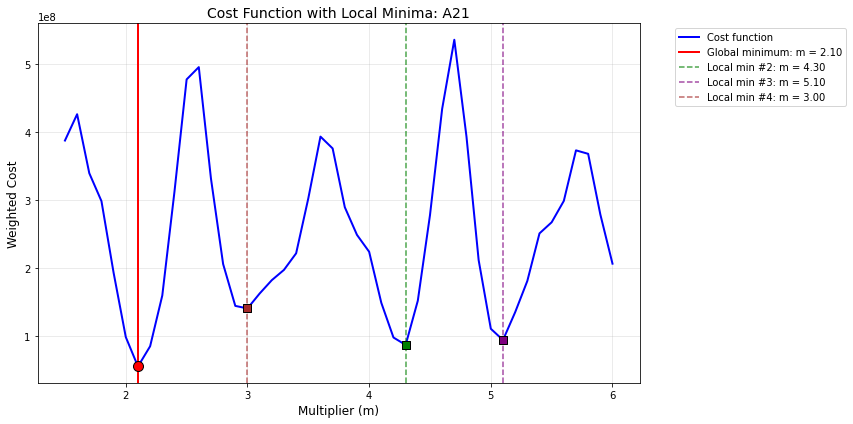


Local Minima Summary for A21:
--------------------------------------------------
#1: m = 2.10, cost = 5.55e+07 (GLOBAL)
#2: m = 4.30, cost = 8.71e+07
#3: m = 5.10, cost = 9.43e+07
#4: m = 3.00, cost = 1.41e+08


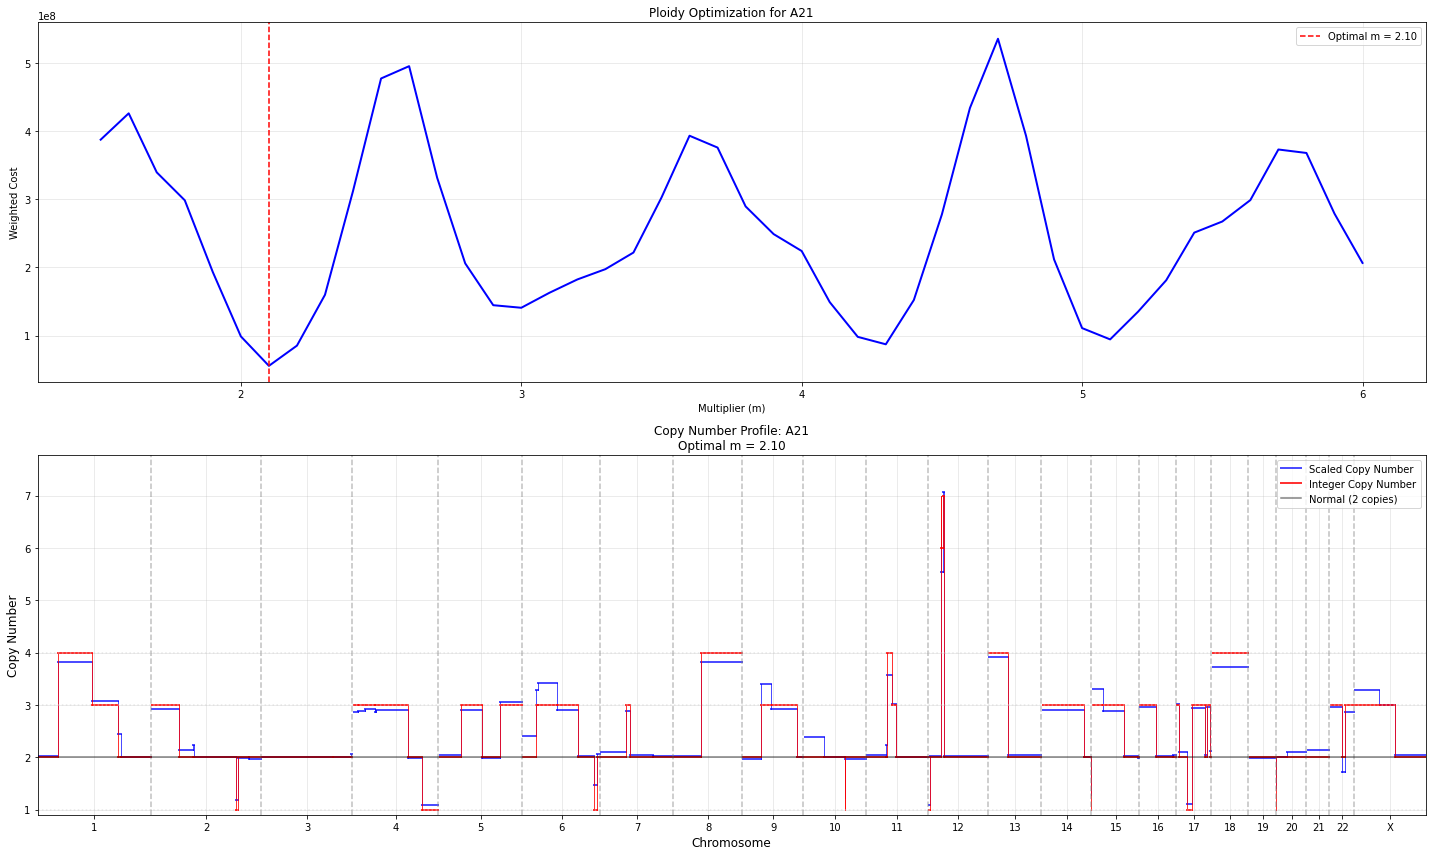

Completed plots for A21

Plotting results for population: A2211


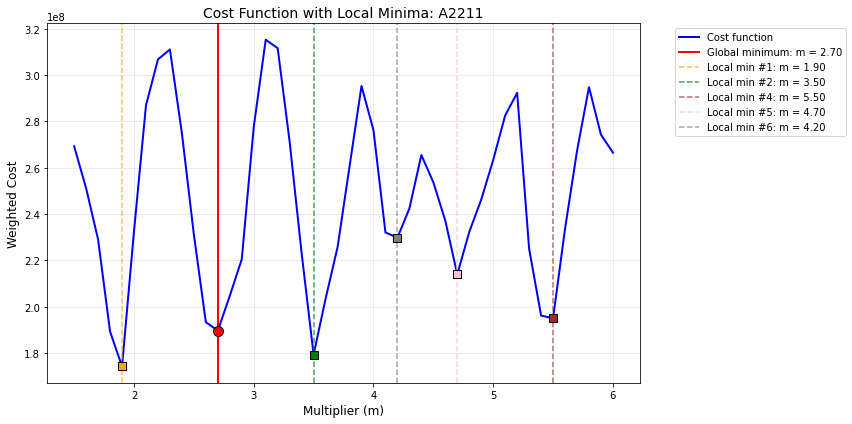


Local Minima Summary for A2211:
--------------------------------------------------
#1: m = 1.90, cost = 1.74e+08
#2: m = 3.50, cost = 1.79e+08
#3: m = 2.70, cost = 1.90e+08 (GLOBAL)
#4: m = 5.50, cost = 1.95e+08
#5: m = 4.70, cost = 2.14e+08
#6: m = 4.20, cost = 2.30e+08


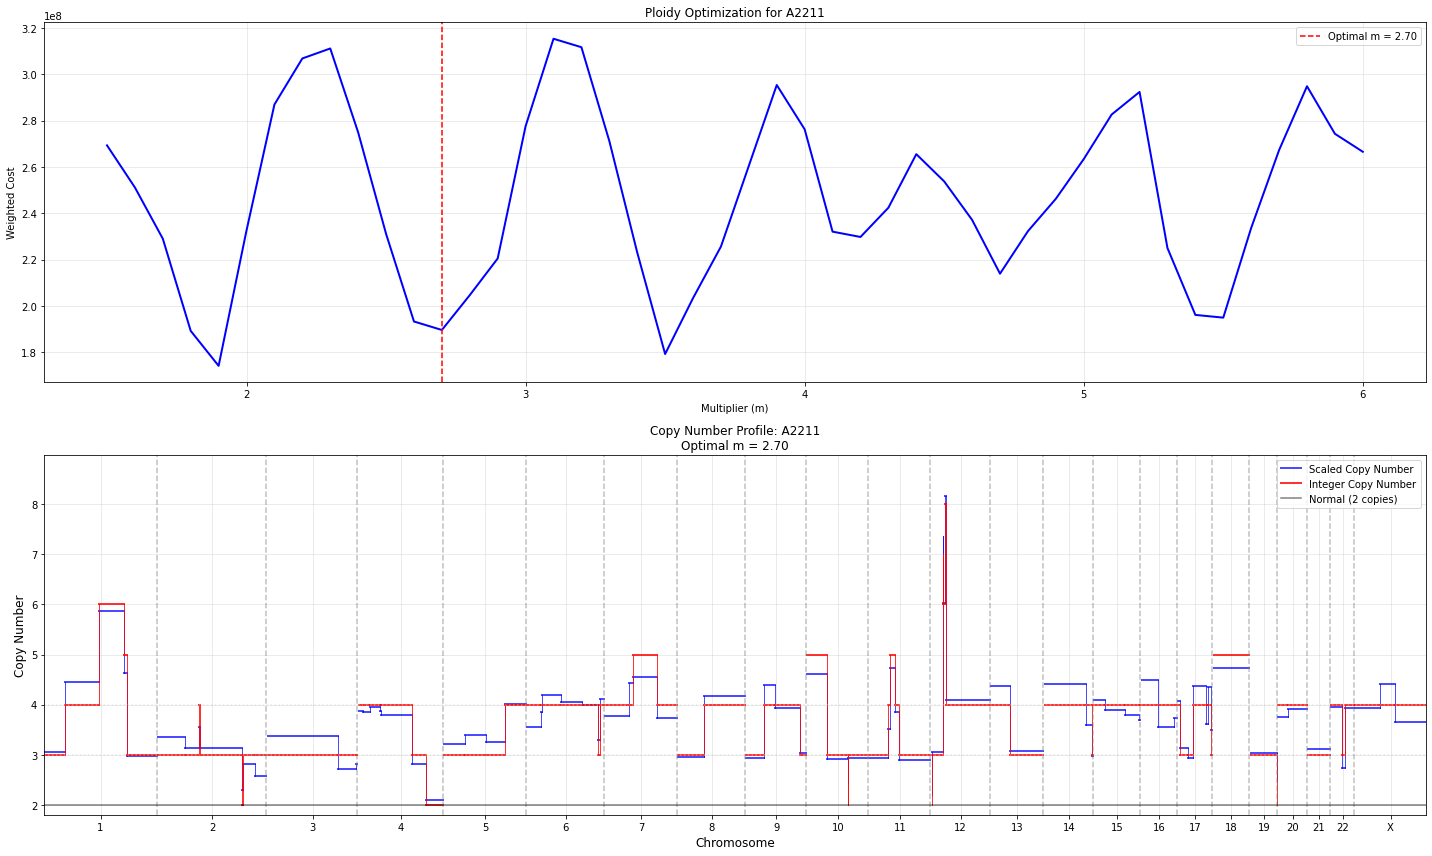

Completed plots for A2211

Plotting results for population: A2212


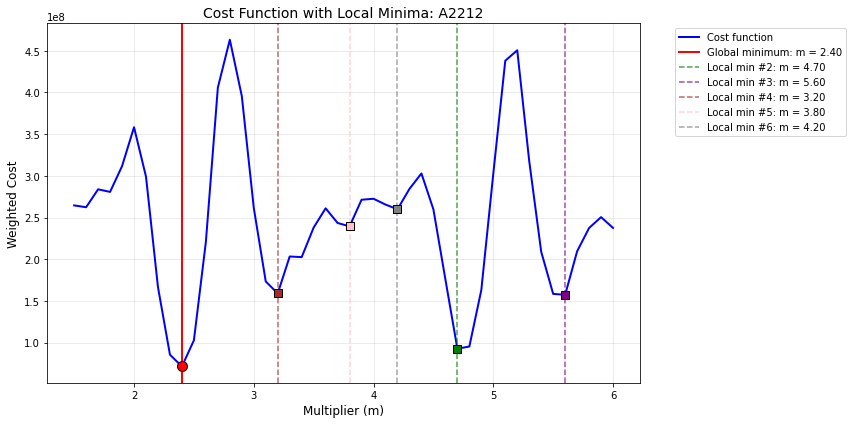


Local Minima Summary for A2212:
--------------------------------------------------
#1: m = 2.40, cost = 7.14e+07 (GLOBAL)
#2: m = 4.70, cost = 9.27e+07
#3: m = 5.60, cost = 1.57e+08
#4: m = 3.20, cost = 1.59e+08
#5: m = 3.80, cost = 2.39e+08
#6: m = 4.20, cost = 2.60e+08


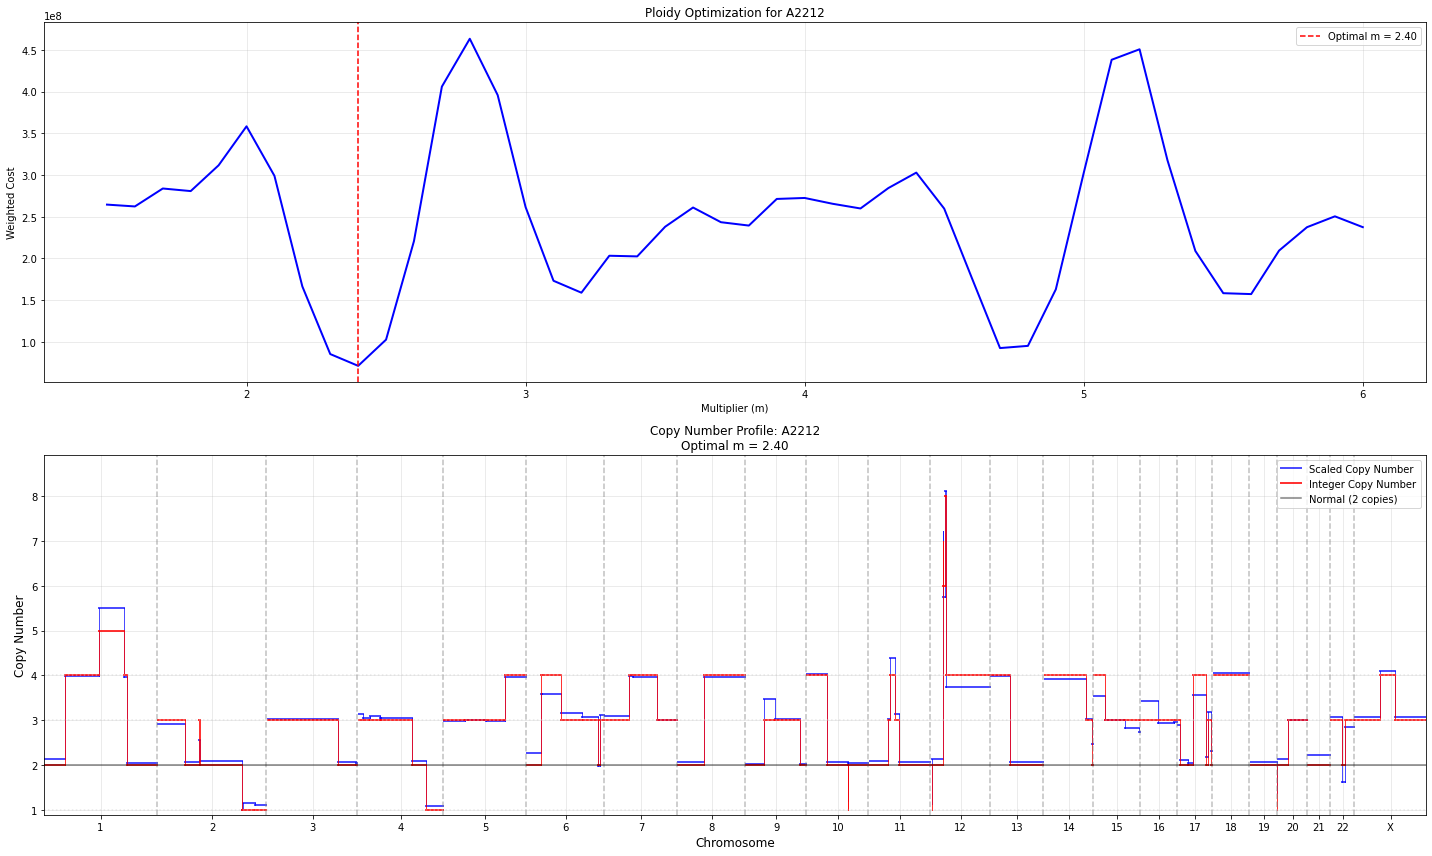

Completed plots for A2212

Plotting results for population: A2221


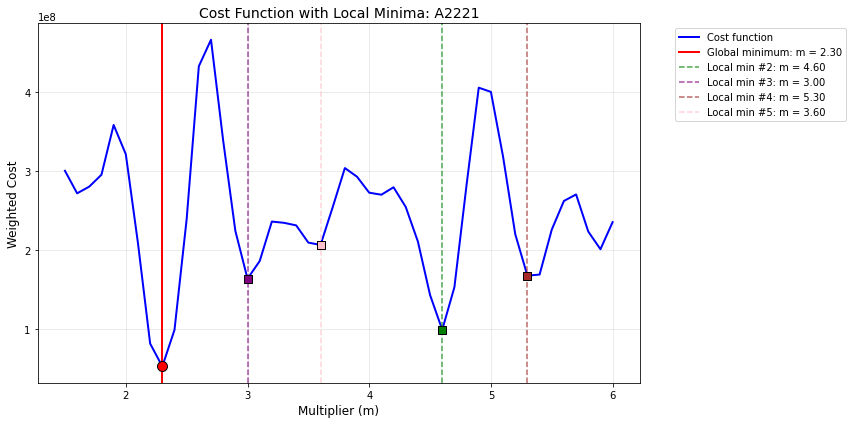


Local Minima Summary for A2221:
--------------------------------------------------
#1: m = 2.30, cost = 5.23e+07 (GLOBAL)
#2: m = 4.60, cost = 9.88e+07
#3: m = 3.00, cost = 1.64e+08
#4: m = 5.30, cost = 1.67e+08
#5: m = 3.60, cost = 2.07e+08


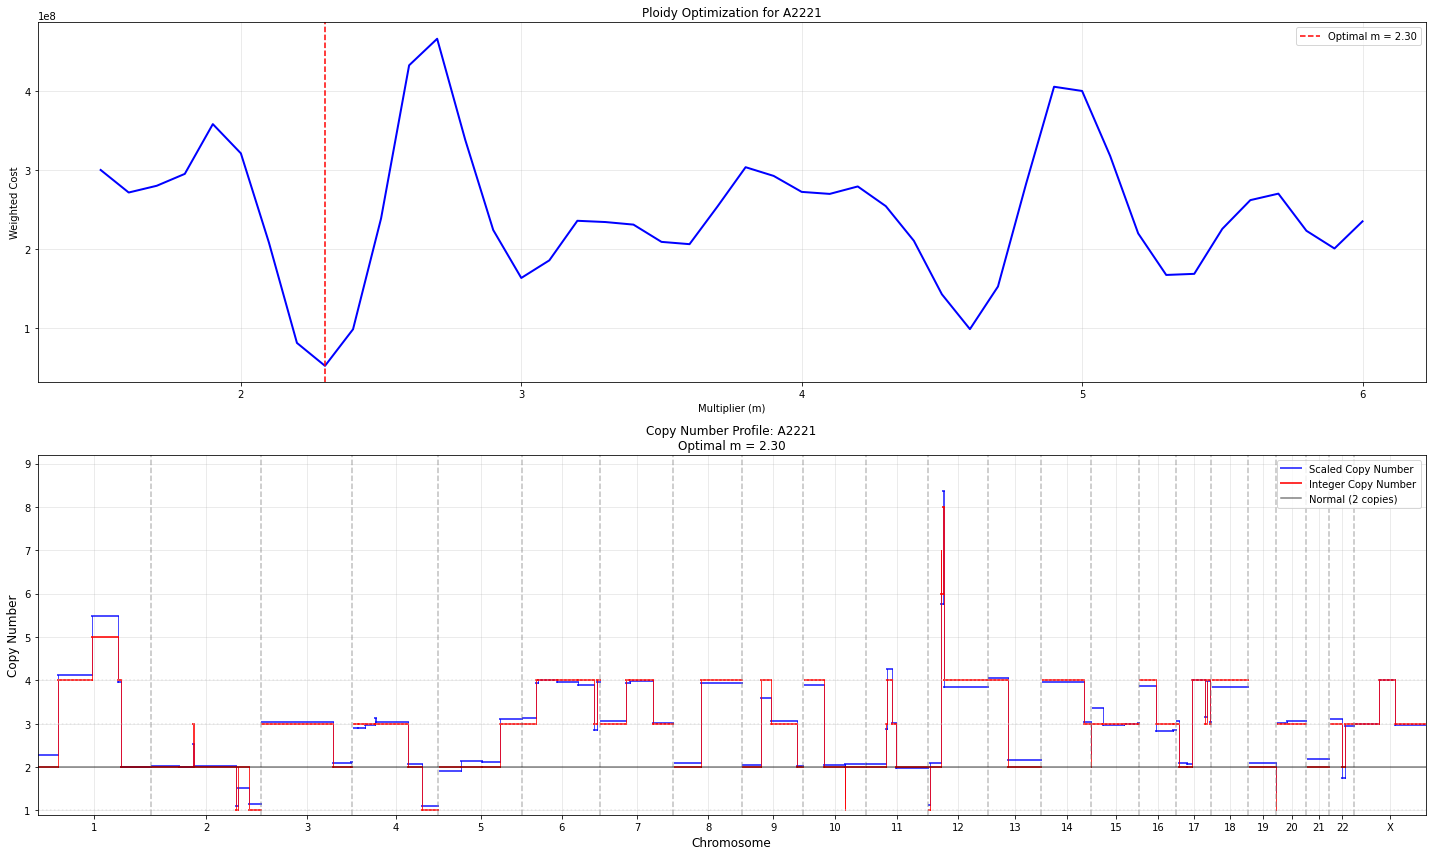

Completed plots for A2221

Plotting results for population: A2222


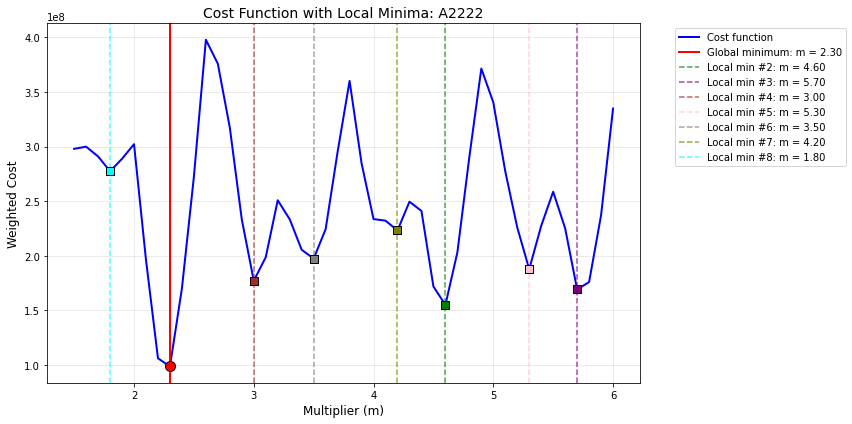


Local Minima Summary for A2222:
--------------------------------------------------
#1: m = 2.30, cost = 9.87e+07 (GLOBAL)
#2: m = 4.60, cost = 1.55e+08
#3: m = 5.70, cost = 1.69e+08
#4: m = 3.00, cost = 1.77e+08
#5: m = 5.30, cost = 1.88e+08
#6: m = 3.50, cost = 1.97e+08
#7: m = 4.20, cost = 2.23e+08
#8: m = 1.80, cost = 2.77e+08


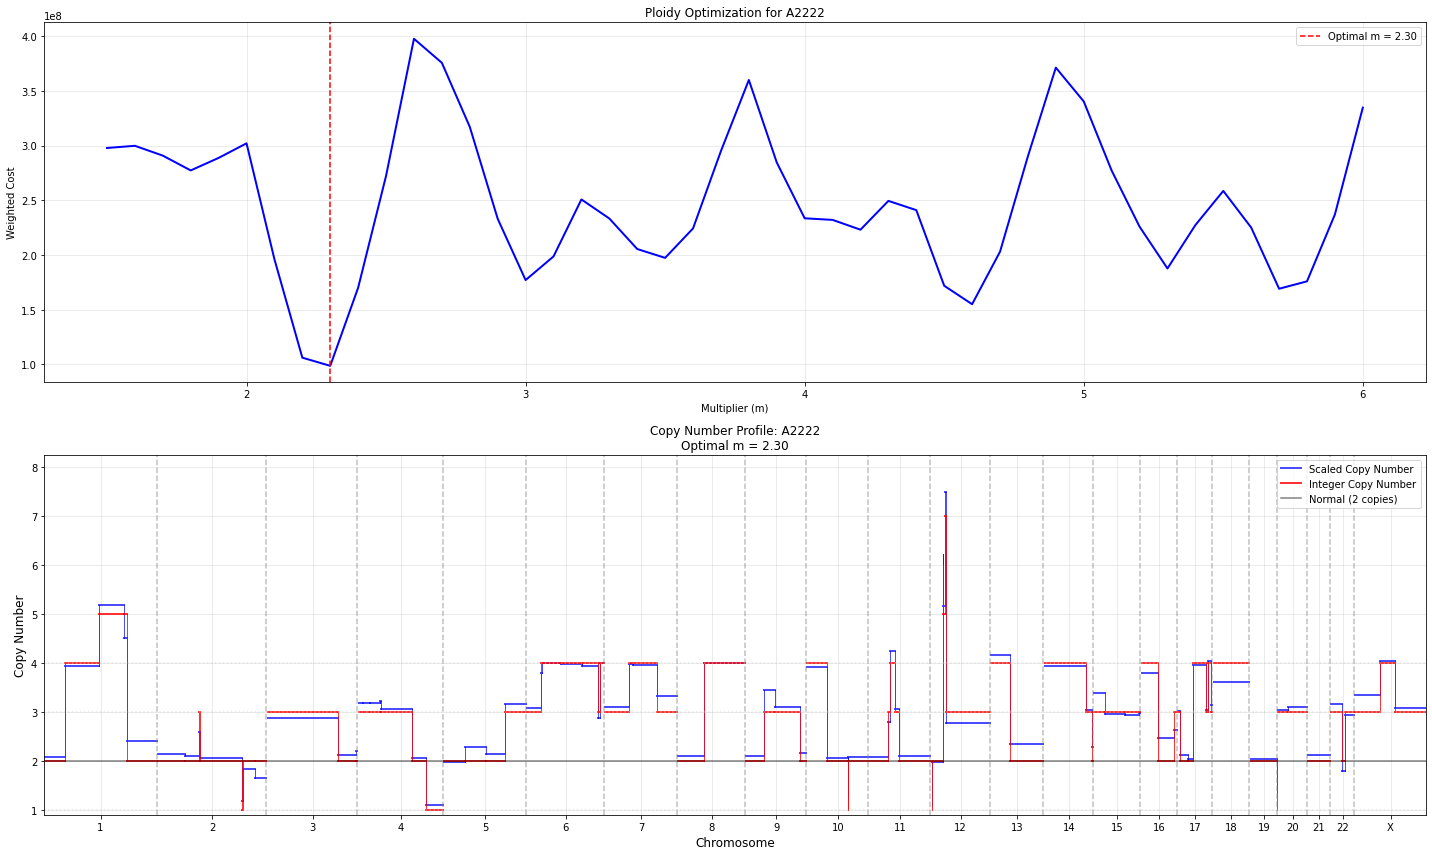

Completed plots for A2222


In [31]:
# Test the plotting functions on your ploidy results
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Plotting results for population: {pop_name}")
    
    # Get the results for this population
    results = ploidy_results_A[pop_name]
    profile_df = profile_dfs_A[pop_name]
    
    # 1. Plot cost function with local minima
    plot_cost_function_with_minima(
        cost_results=results['cost_results'],
        local_minima=results['local_minima'],
        pop_name=pop_name,
        optimal_m=results['optimal_multiplier']
    )
    
    # 2. Plot the full ploidy optimization (cost function + copy number profile)
    pop_col = f"{pop_name}_ratio"  # Reconstruct the column name
    plot_ploidy_optimization(
        results_df=profile_df,
        cost_results=results['cost_results'],
        optimal_m=results['optimal_multiplier'],
        pop_col=pop_col
    )
    
    print(f"Completed plots for {pop_name}")

In [32]:
import os
import pandas as pd

# Define the parquet file path
parquet_file = f"../data/{tumor}/hap_count_df.parquet"

# Check if parquet file exists, if so load it, otherwise create and save it
if os.path.exists(parquet_file):
    print("Loading hap_count_df from parquet file...")
    hap_count_df = pd.read_parquet(parquet_file)
    print(f"Loaded hap_count_df with shape: {hap_count_df.shape}")
else:
    print("Parquet file not found. Creating hap_count_df from source data...")
    
    hap_count_df = pd.read_csv(f"/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/{tumor}/per_cell_hap_count.txt", sep = "\t")
    binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
    bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
    chrom_dict = dict(zip(binning.index, binning["bin.chrom"]))

    hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])
    hap_count_df["chrom"] = hap_count_df["bin"].apply(lambda x : chrom_dict[x])
    hap_count_df= hap_count_df[["chrom", "abspos","bin", "cell", "hap_count","Total"]]

    print(f"Created hap_count_df with shape: {hap_count_df.shape}")
    
    # Save as parquet for future use
    print("Saving hap_count_df as parquet file...")
    hap_count_df.to_parquet(parquet_file, index=False)
    
    # Check file size
    file_size = os.path.getsize(parquet_file)
    print(f"Saved parquet file: {file_size:,} bytes ({file_size/1024**2:.2f} MB)")

print("hap_count_df ready for analysis!")

Loading hap_count_df from parquet file...
Loaded hap_count_df with shape: (8605992, 6)
hap_count_df ready for analysis!


In [33]:
hap_count_df.head()

,chrom,abspos,bin,cell,hap_count,Total
0,chr1,0,0,AATGAGGATGCAACACA,3,6
1,chr1,1925685,1,AATGAGGATGCAACACA,0,2
2,chr1,3106884,2,AATGAGGATGCAACACA,0,2
3,chr1,4351684,3,AATGAGGATGCAACACA,7,7
4,chr1,5438445,4,AATGAGGATGCAACACA,0,0


In [34]:
bin_to_chrom_dict = dict(zip(hap_count_df[["chrom", "bin"]].drop_duplicates()["bin"].values, hap_count_df[["chrom", "bin"]].drop_duplicates()["chrom"].values))

In [35]:
example = list(A_dict.keys())[1]

In [36]:
# # Example usage for A211 with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,  # or use ploidy_results_A[example]['optimal_multiplier']
#     local_m=3.1,   # pick from ploidy_results_A[example]['local_minima']
#     pop_col=f'{example}_ratio'
# )

In [37]:
#Get all cells in example
example_cells = A_dict[example]['cells']
#Filter hap_count_df for these cells
example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
example_hap_ratio['hap_ratio'] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
example_hap_ratio['folded'] = example_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information    
example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])

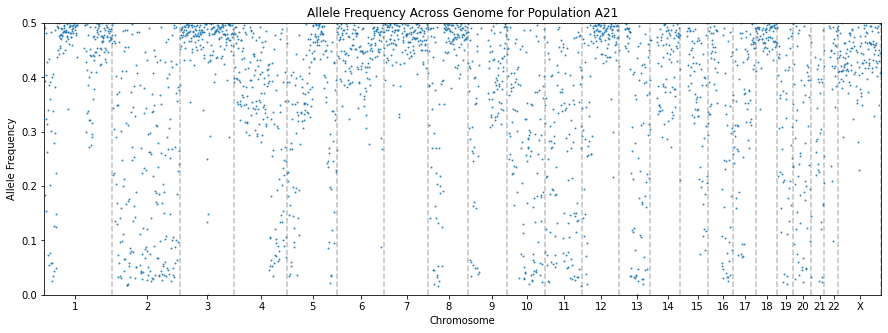

In [38]:
# plot the folded allele frequency along the genome
example_hap_ratio_sorted = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(example_hap_ratio_sorted['abspos'], example_hap_ratio_sorted['folded'], s=1, alpha=0.8)
plt.xlabel('Chromosome')
plt.ylabel('Allele Frequency')
plt.title('Allele Frequency Across Genome for Population ' + example)
# Add vertical lines for chromosome boundaries
chrom_boundaries = example_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = example_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(example_hap_ratio_sorted['abspos'].min(), example_hap_ratio_sorted['abspos'].max())
plt.show()

In [39]:
hap_df_dict = {}
hap_summary_df = pd.DataFrame()
for pop_name in A_dict.keys():
    #Get all cells in example
    example_cells = A_dict[pop_name]['cells']
    #Filter hap_count_df for these cells
    example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
    # compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
    example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
    example_hap_ratio['hap_ratio_'+pop_name] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
    example_hap_ratio.rename(columns={'hap_count': 'hap_count_'+pop_name, 'Total': 'Total_'+pop_name}, inplace=True)
    example_hap_ratio['folded_'+pop_name] = example_hap_ratio['hap_ratio_'+pop_name].apply(lambda x: min(x, 1-x))
    # Add chromosome information    
    example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])
    example_hap_ratio = example_hap_ratio[["bin", "abspos", "chrom", 'hap_ratio_'+pop_name, 'folded_'+pop_name, 'hap_count_'+pop_name, 'Total_'+pop_name]]
    hap_df_dict[pop_name] = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
    if hap_summary_df.empty:
        hap_summary_df = example_hap_ratio.sort_values(by=['chrom', 'abspos']).copy()
    else:
        hap_summary_df = hap_summary_df.merge(
            example_hap_ratio,
            on=['bin', 'abspos', 'chrom'],
            suffixes=('', f'_{pop_name}')
        )


In [40]:
hap_summary_df

,bin,abspos,chrom,hap_ratio_A1,folded_A1,hap_count_A1,Total_A1,hap_ratio_A21,folded_A21,hap_count_A21,...,hap_count_A2212,Total_A2212,hap_ratio_A2221,folded_A2221,hap_count_A2221,Total_A2221,hap_ratio_A2222,folded_A2222,hap_count_A2222,Total_A2222
0,0,0,chr1,0.471487,0.471487,3208,6804,0.505090,0.494910,645,...,131,273,0.448944,0.448944,255,568,0.490050,0.490050,197,402
1,1,1925685,chr1,0.531539,0.468461,3278,6167,0.815608,0.184392,1181,...,226,280,0.843994,0.156006,541,641,0.779343,0.220657,332,426
2,2,3106884,chr1,0.459994,0.459994,4628,10061,0.606208,0.393792,1250,...,260,408,0.567718,0.432282,612,1078,0.641064,0.358936,434,677
3,3,4351684,chr1,0.534696,0.465304,6149,11500,0.491308,0.491308,1187,...,206,378,0.466555,0.466555,558,1196,0.472914,0.472914,323,683
4,4,5438445,chr1,0.451244,0.451244,1777,3938,0.481576,0.481576,379,...,40,103,0.408219,0.408219,149,365,0.482014,0.482014,134,278
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2483,2483,3029874983,chrX,0.453773,0.453773,2135,4705,0.497802,0.497802,453,...,124,316,0.371025,0.371025,210,566,0.374648,0.374648,133,355
2484,2484,3031129344,chrX,0.470954,0.470954,2351,4992,0.445402,0.445402,465,...,139,287,0.576224,0.423776,412,715,0.536131,0.463869,230,429
2485,2485,3032248949,chrX,0.470799,0.470799,919,1952,0.407186,0.407186,136,...,43,157,0.293040,0.293040,80,273,0.384181,0.384181,68,177
2486,2486,3033693492,chrX,0.500000,0.500000,1025,2050,0.437778,0.437778,197,...,63,133,0.486301,0.486301,142,292,0.598837,0.401163,103,172


In [41]:
hap_summary_df.to_csv(f"../data/{tumor}/{tumor}_haplotype_summary_by_population_A.txt", sep="\t", index=False)

In [42]:
normal_A

'A1'

In [43]:
#Get all cells in A1
normal_cells = A_dict[normal_A]['cells']
#Filter hap_count_df for these cells
normal_hap_df = hap_count_df[hap_count_df['cell'].isin(normal_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
normal_hap_ratio = normal_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
normal_hap_ratio['hap_ratio'] = normal_hap_ratio['hap_count'] / normal_hap_ratio['Total']
normal_hap_ratio['folded'] = normal_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
normal_hap_ratio["chrom"] = normal_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])

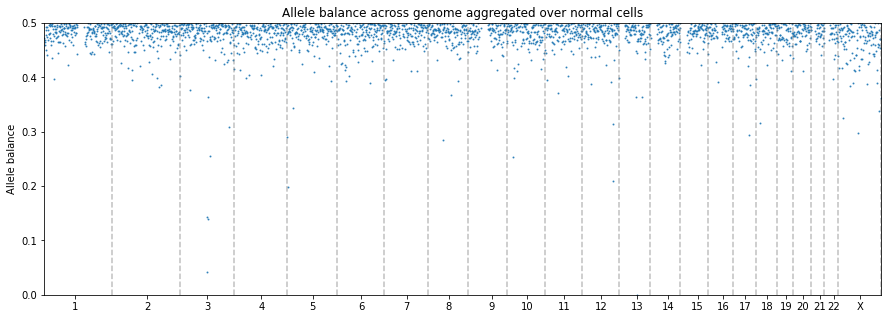

In [44]:
# plot the folded allele frequency along the genome
normal_hap_ratio_sorted = normal_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(normal_hap_ratio_sorted['abspos'], normal_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over normal cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = normal_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = normal_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(normal_hap_ratio_sorted['abspos'].min(), normal_hap_ratio_sorted['abspos'].max())
plt.show()

In [45]:
A_df.head()

,cell,population,normal_population
0,AAAACCAACCTGATAAC,A1,True
1,AAAACCAATTTCAGTAC,A1,True
2,AAAACCAGTGAGTCTAC,A1,True
3,AAAACCATGAGGAGAAG,A1,True
4,AAAACCGAACCCGTACA,A1,True


In [46]:
#Get all tumor cells in (not A1)
tumor_cells = A_df[A_df['population'] != normal_A]['cell'].tolist()
#Filter hap_count_df for these cells
tumor_hap_df = hap_count_df[hap_count_df['cell'].isin(tumor_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
tumor_hap_ratio = tumor_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
tumor_hap_ratio['hap_ratio'] = tumor_hap_ratio['hap_count'] / tumor_hap_ratio['Total']
tumor_hap_ratio['folded'] = tumor_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
tumor_hap_ratio["chrom"] = tumor_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])


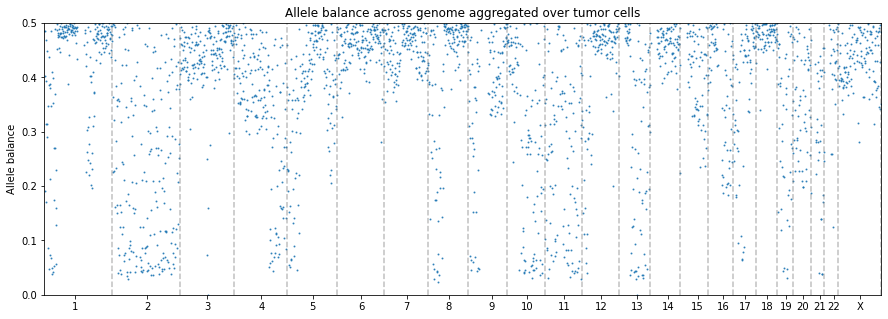

In [47]:
# plot the folded allele frequency along the genome
tumor_hap_ratio_sorted = tumor_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(tumor_hap_ratio_sorted['abspos'], tumor_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over tumor cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(tumor_hap_ratio_sorted['abspos'].min(), tumor_hap_ratio_sorted['abspos'].max())
plt.show()

In [48]:
# # Example usage for example with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,
#     local_m=3.1,
#     pop_col=example + '_ratio',
#     hap_count_df=hap_count_df,
#     cells=A_dict[example]['cells']
# )


Creating ploidy comparison for population: A21


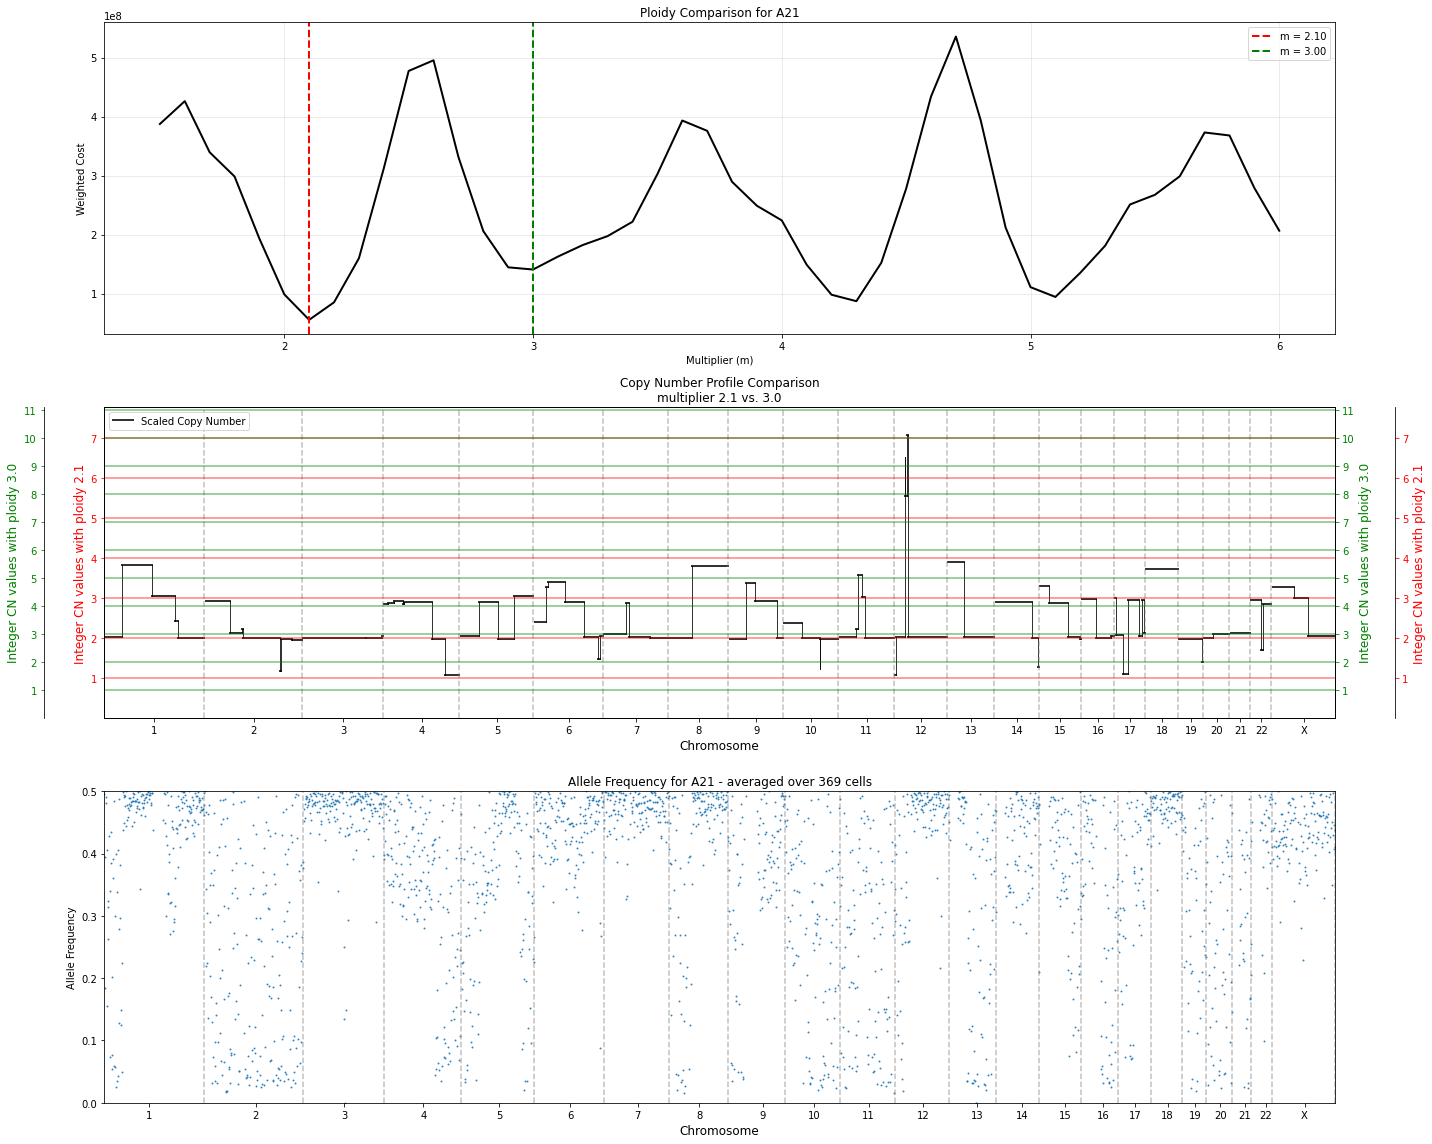

Compared 2.10 vs 3.00 for A21

Creating ploidy comparison for population: A2211


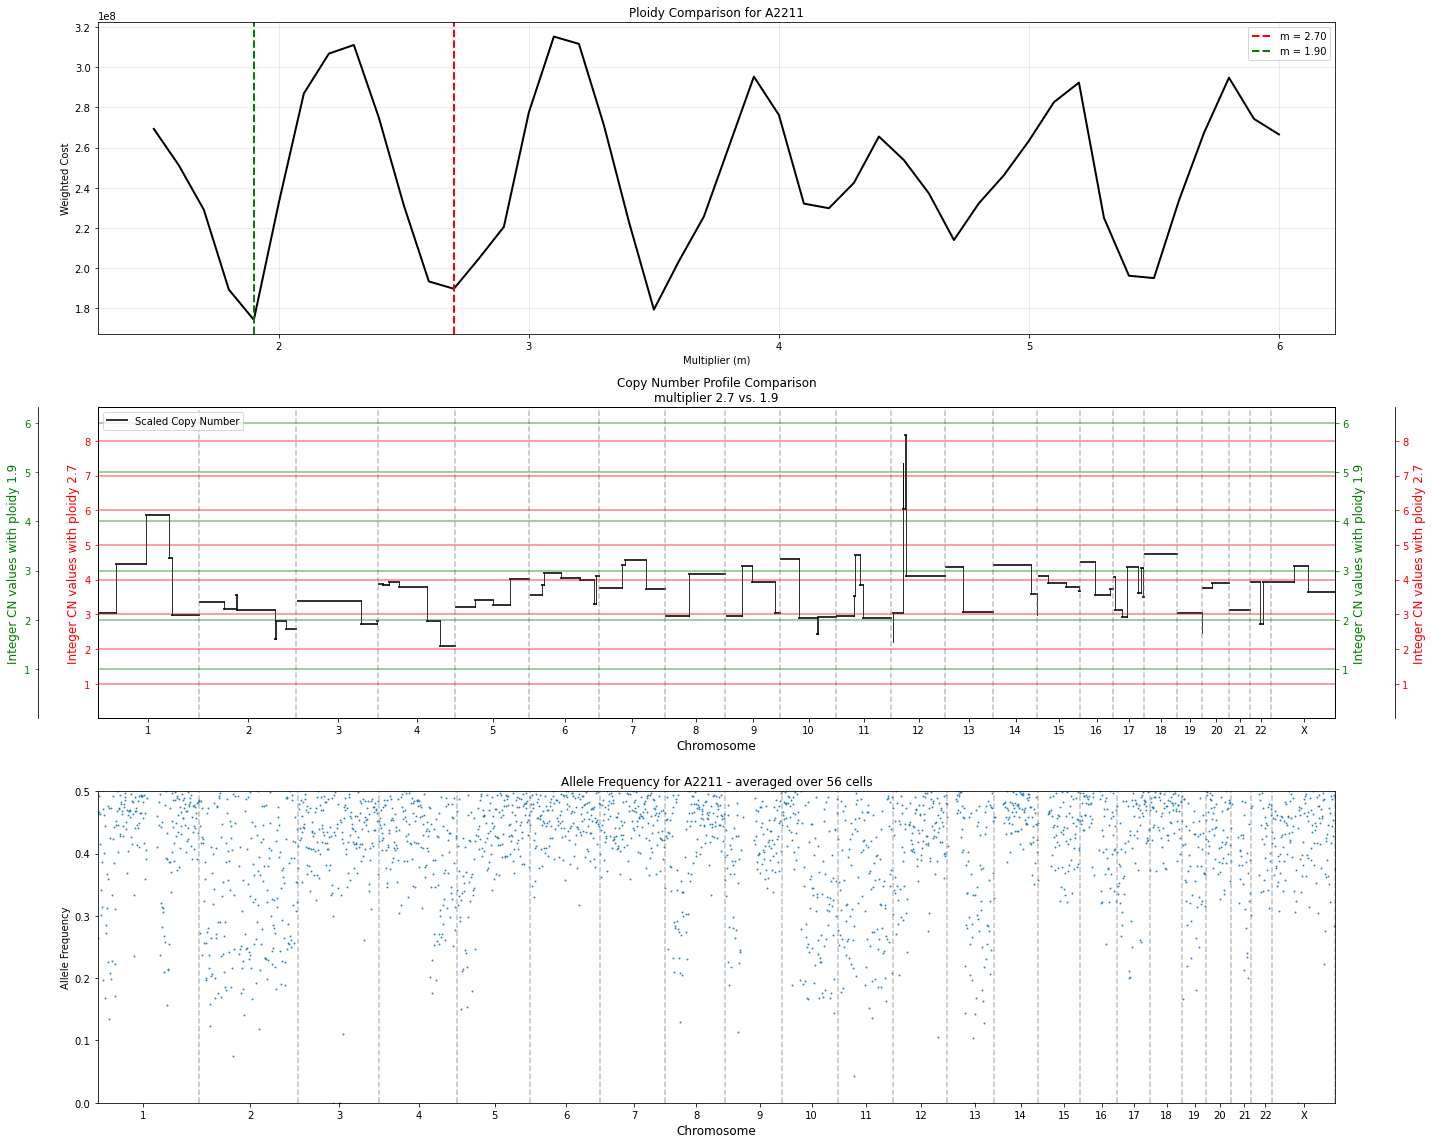

Compared 2.70 vs 1.90 for A2211

Creating ploidy comparison for population: A2212


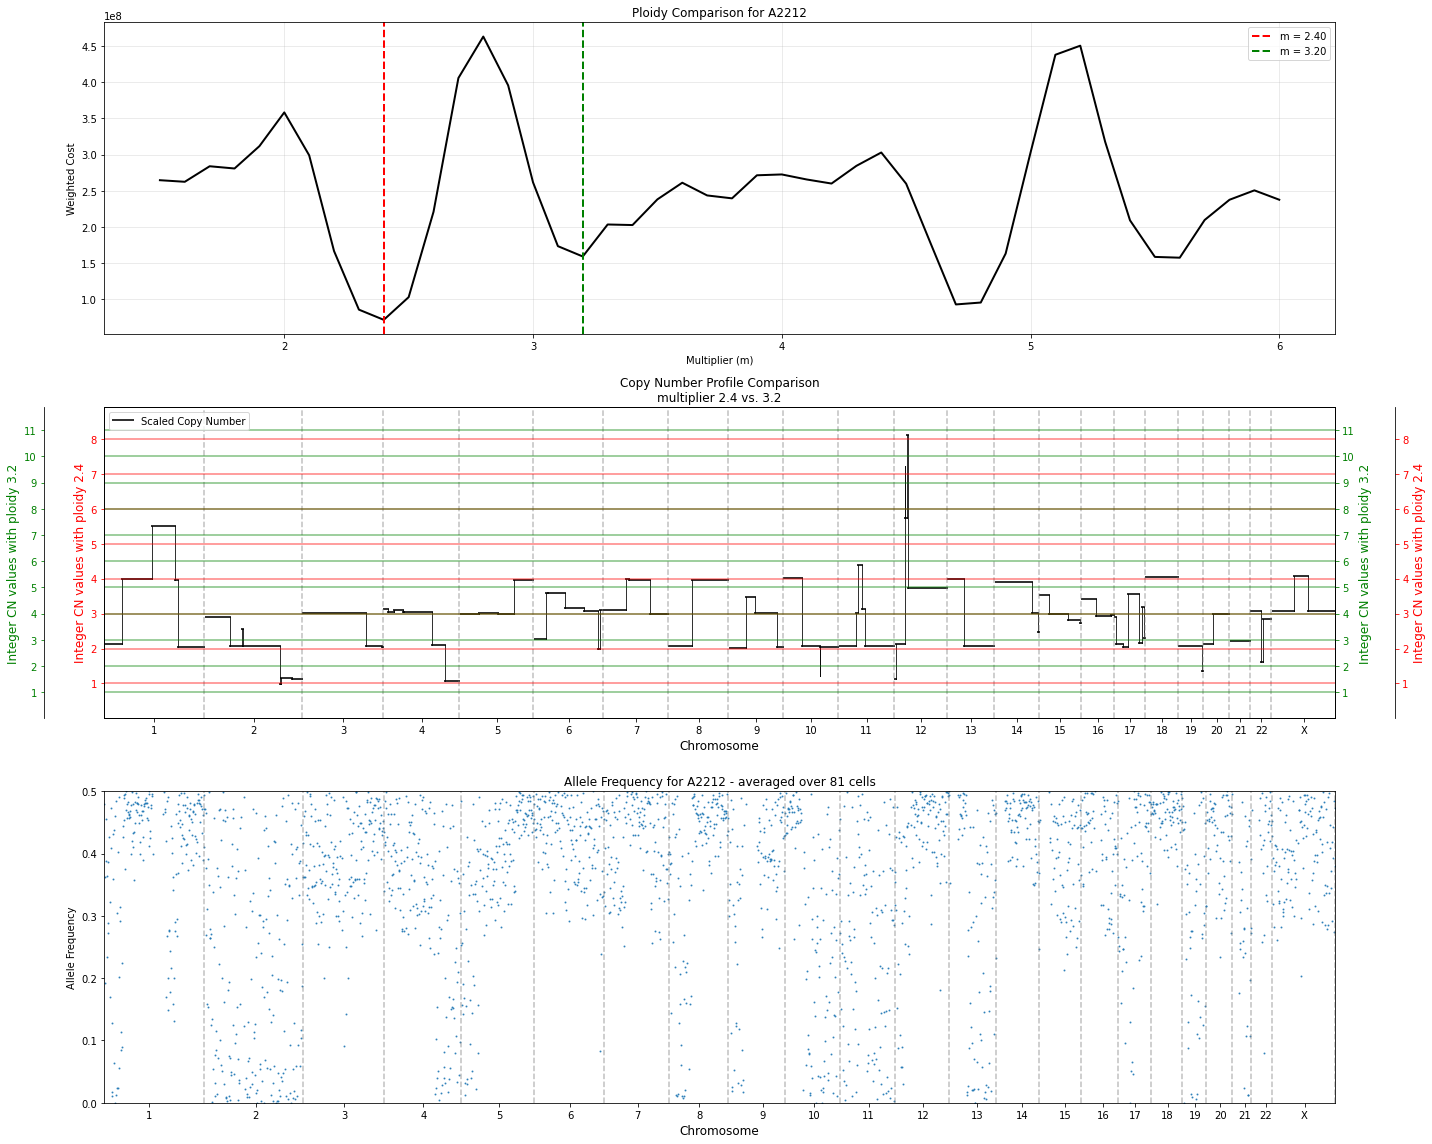

Compared 2.40 vs 3.20 for A2212

Creating ploidy comparison for population: A2221


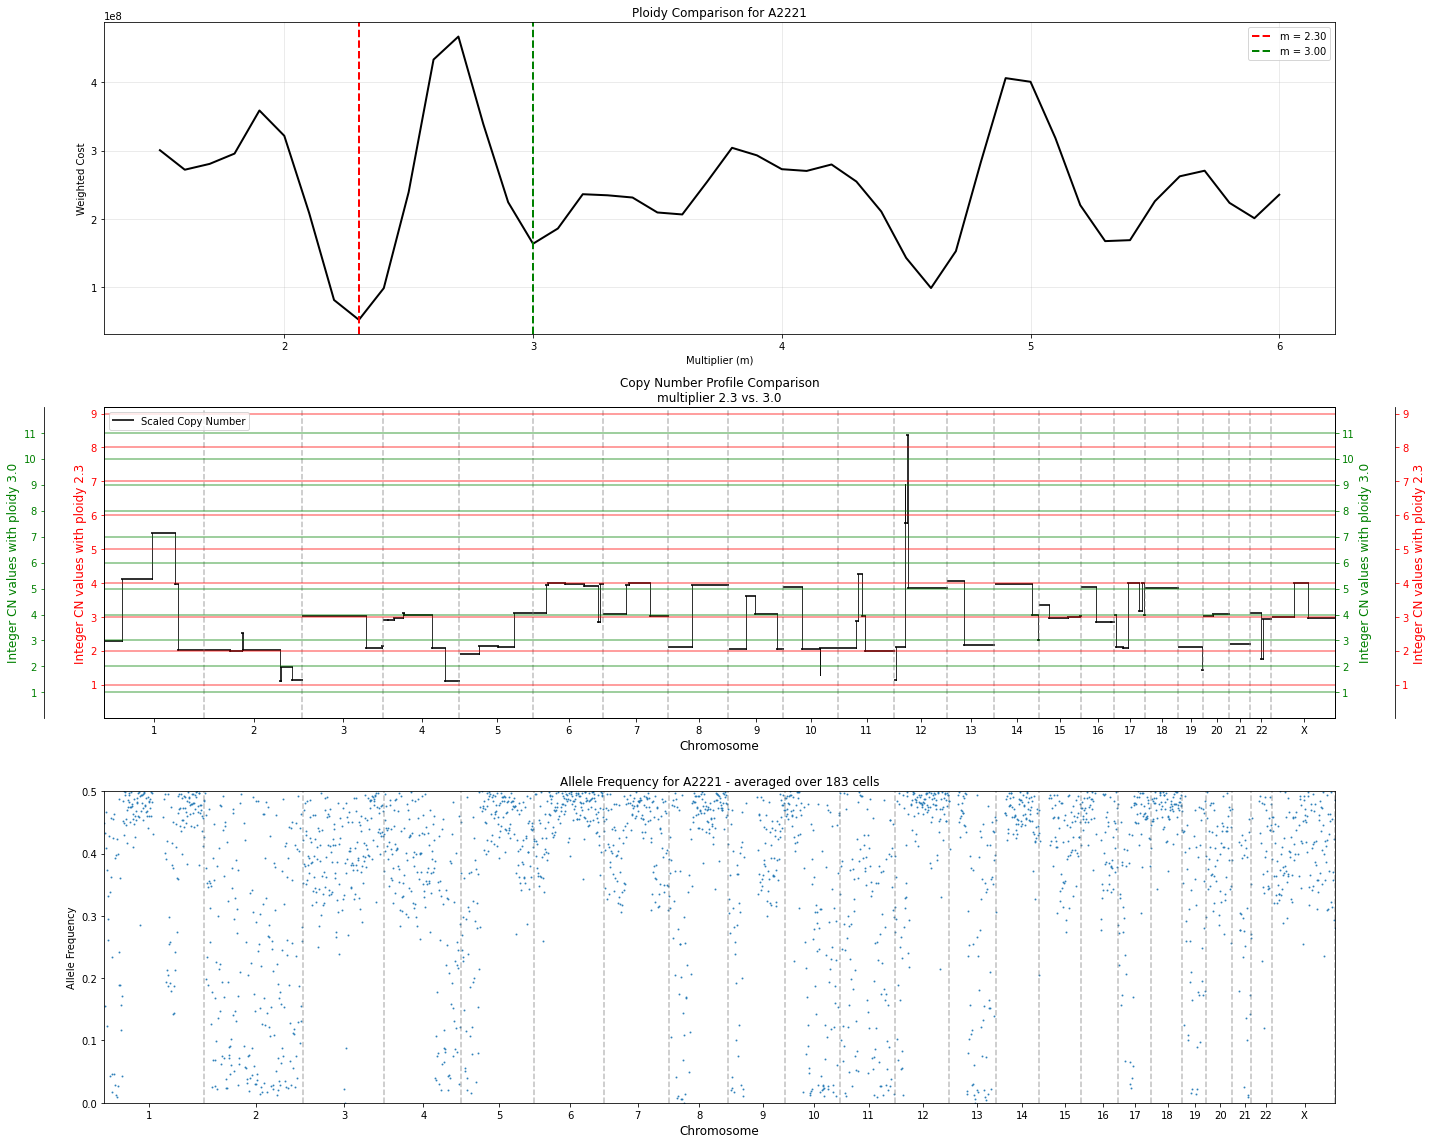

Compared 2.30 vs 3.00 for A2221

Creating ploidy comparison for population: A2222


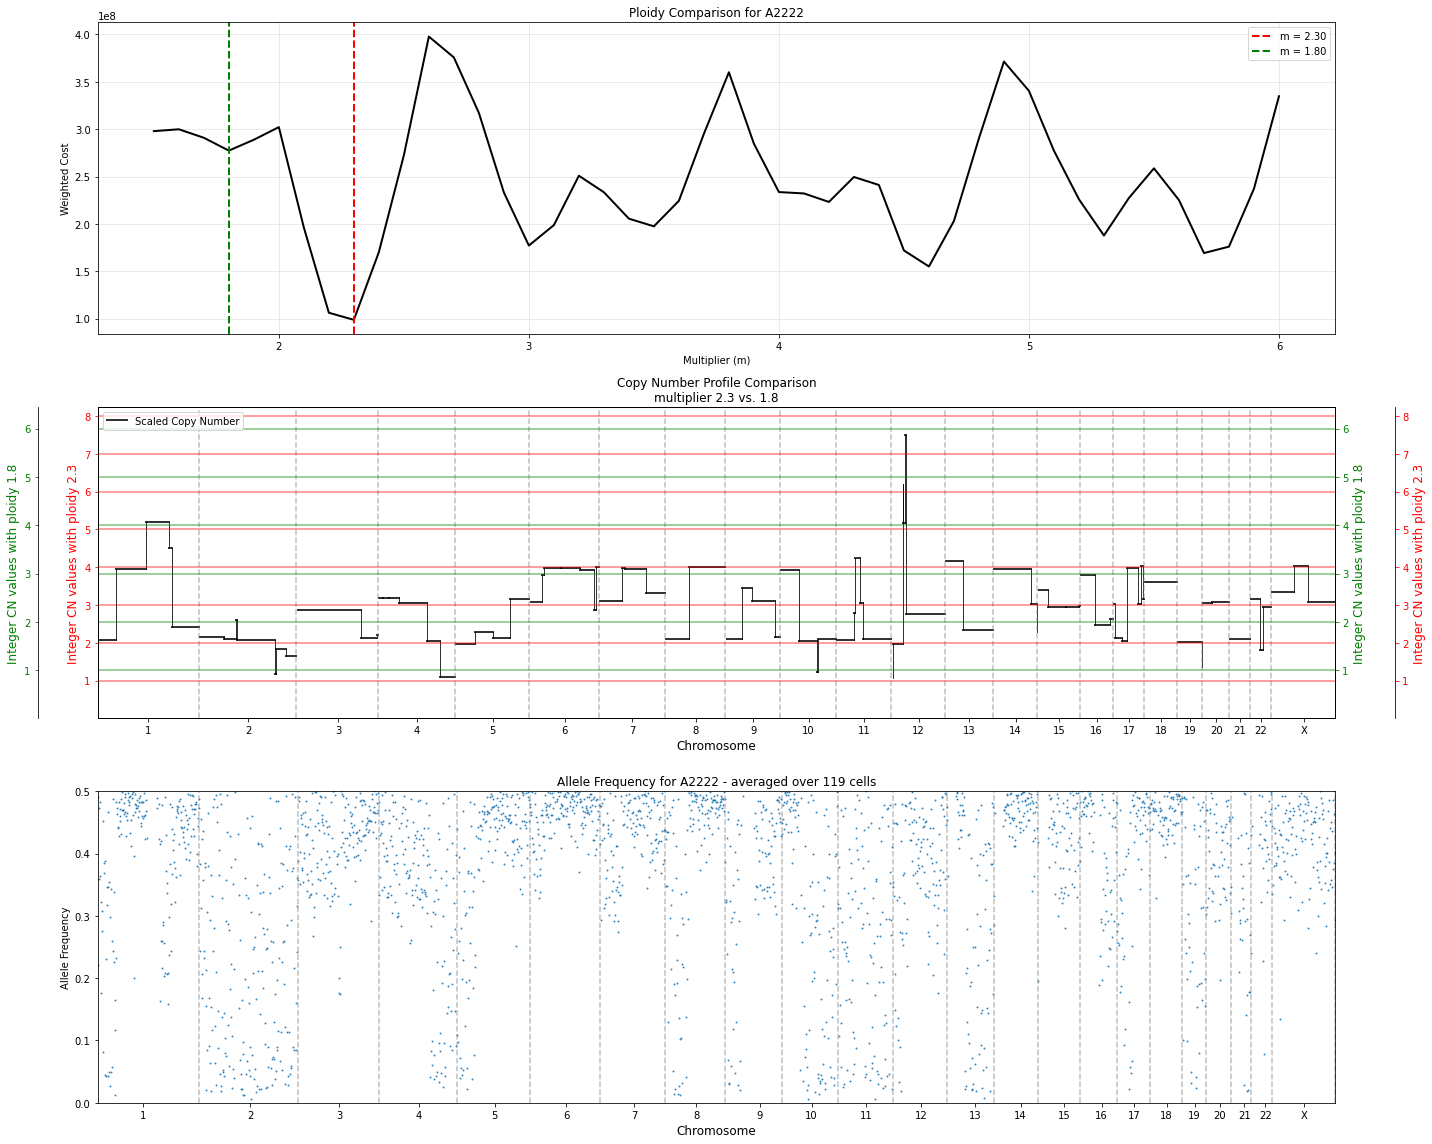

Compared 2.30 vs 1.80 for A2222


In [49]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to ploidy 2 (that's not the global minimum)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Pick the one closest to 2.0
        second_best_m = min(other_minima, key=lambda x: abs(x - 2.0))
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")


Creating ploidy comparison for population: A21


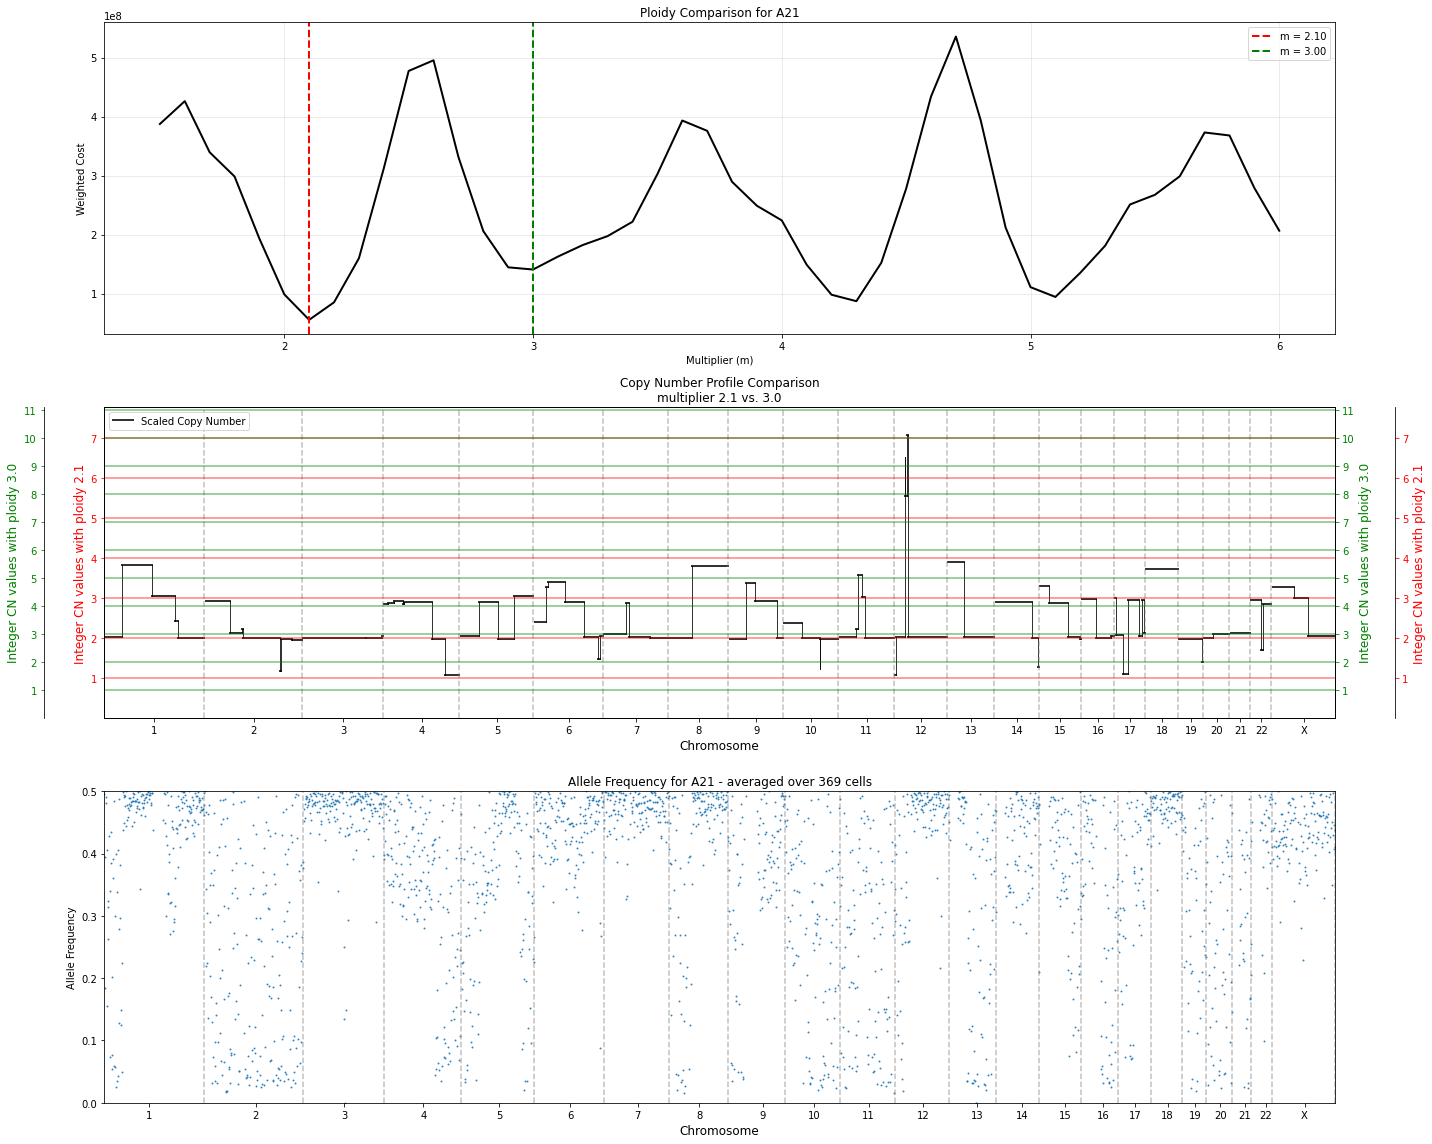

Compared 2.10 vs 3.00 for A21

Creating ploidy comparison for population: A2211


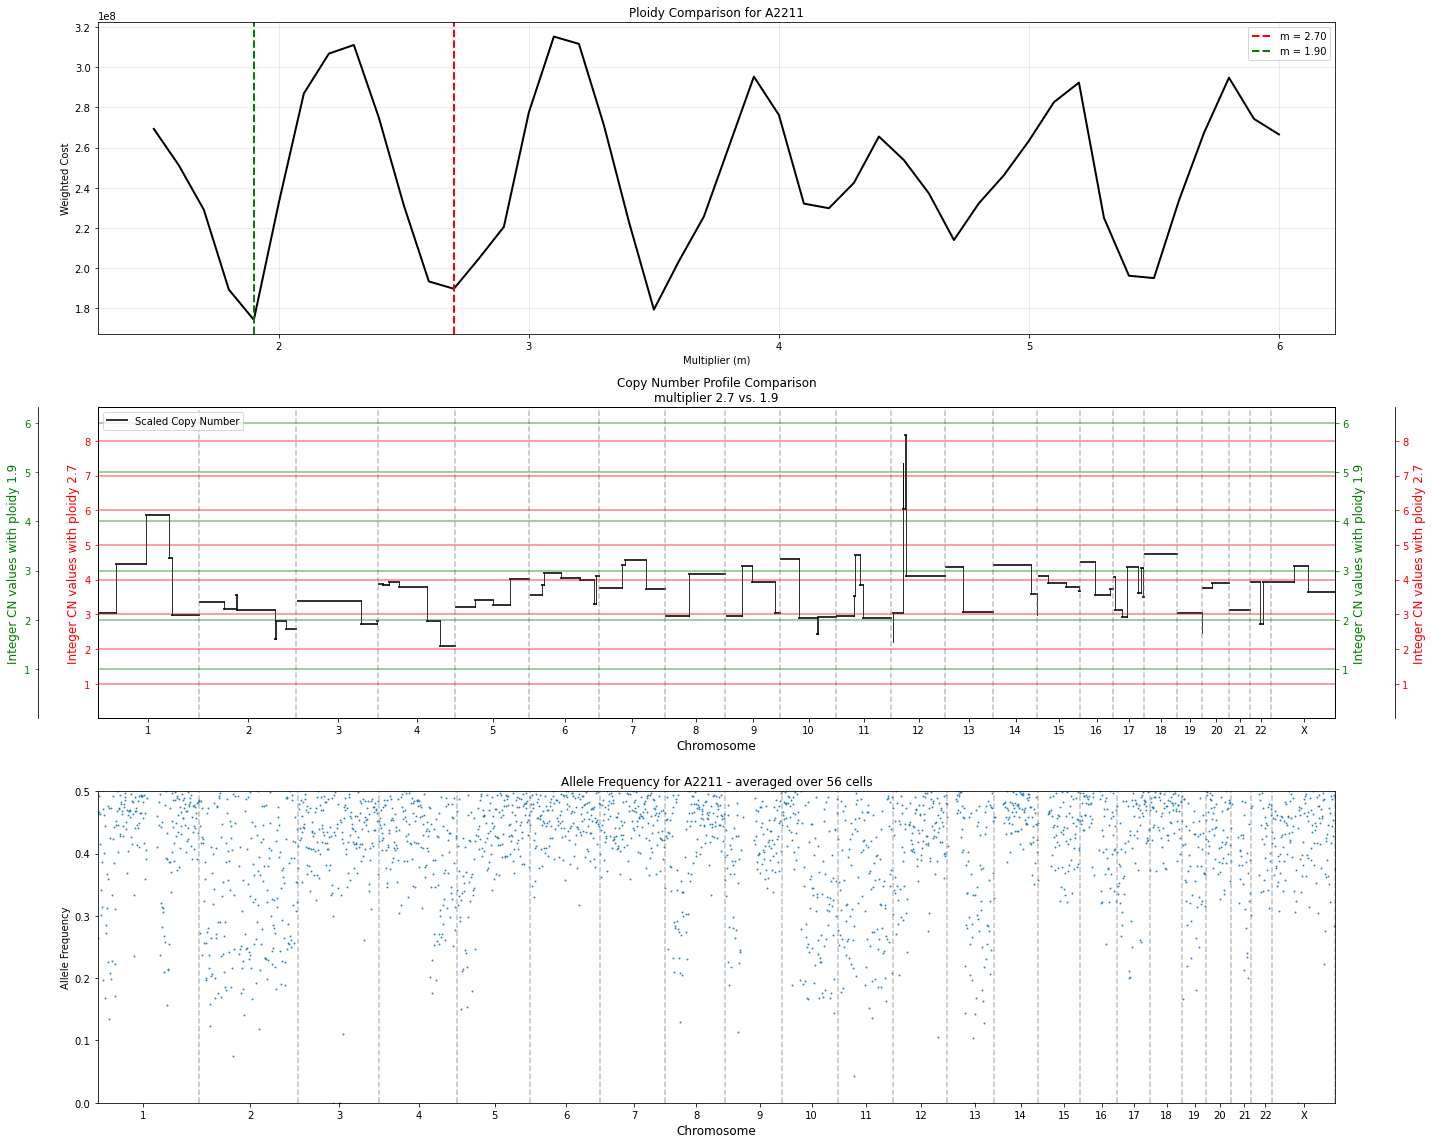

Compared 2.70 vs 1.90 for A2211

Creating ploidy comparison for population: A2212


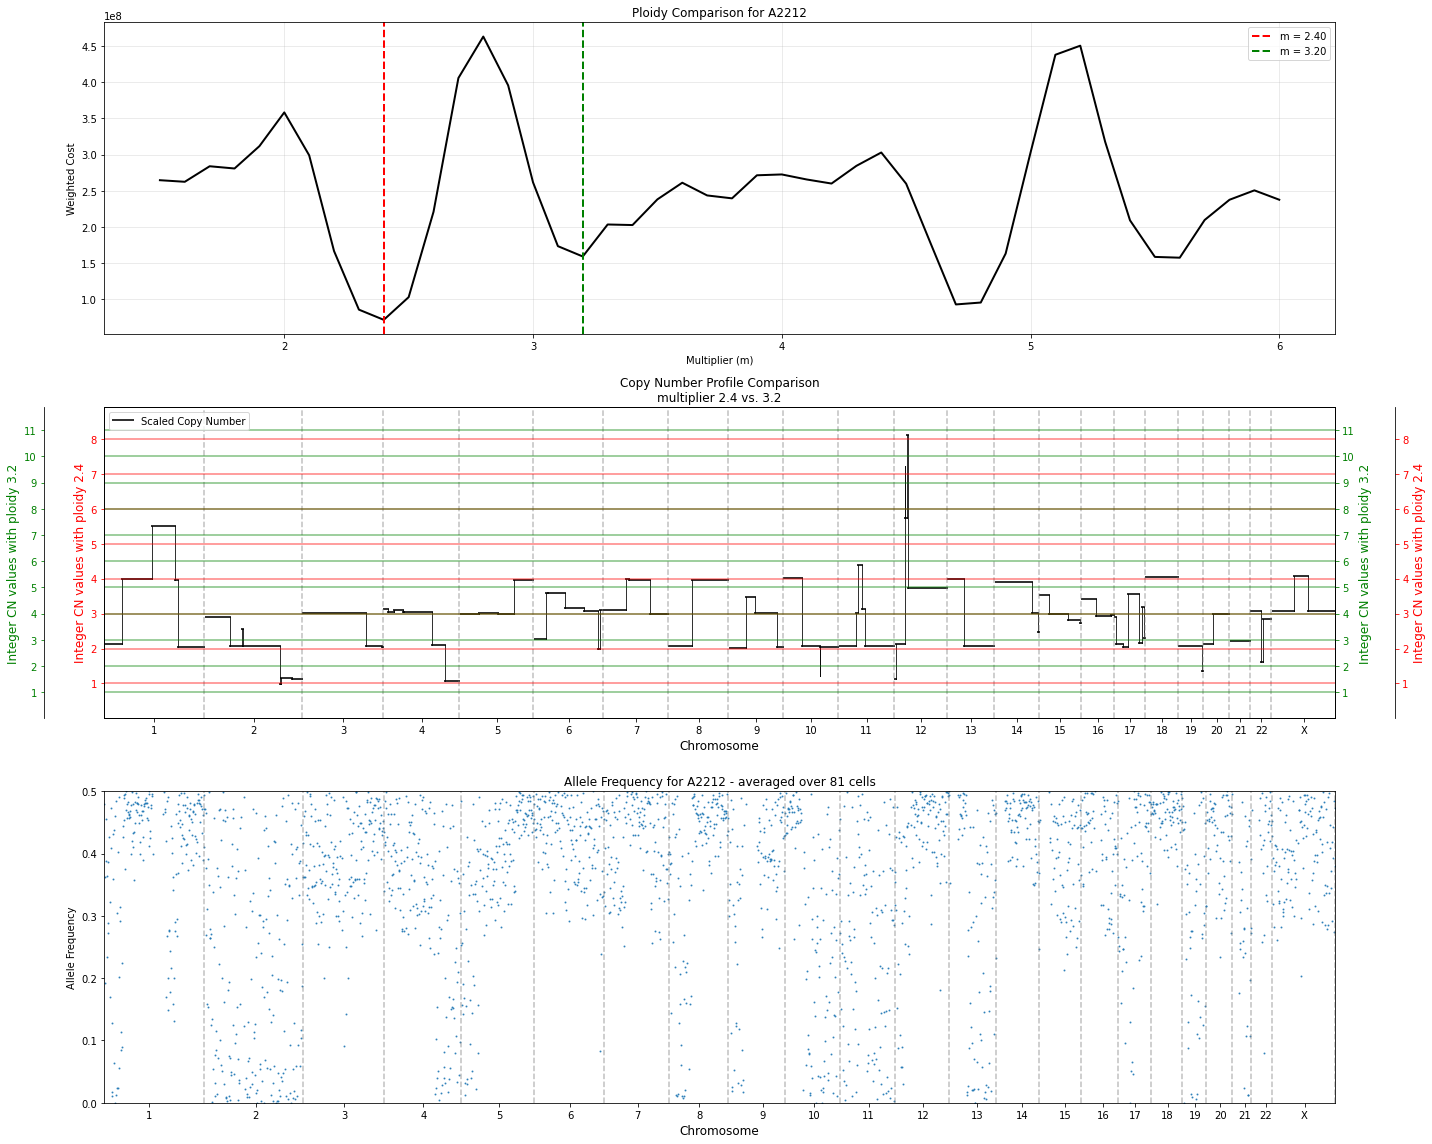

Compared 2.40 vs 3.20 for A2212

Creating ploidy comparison for population: A2221


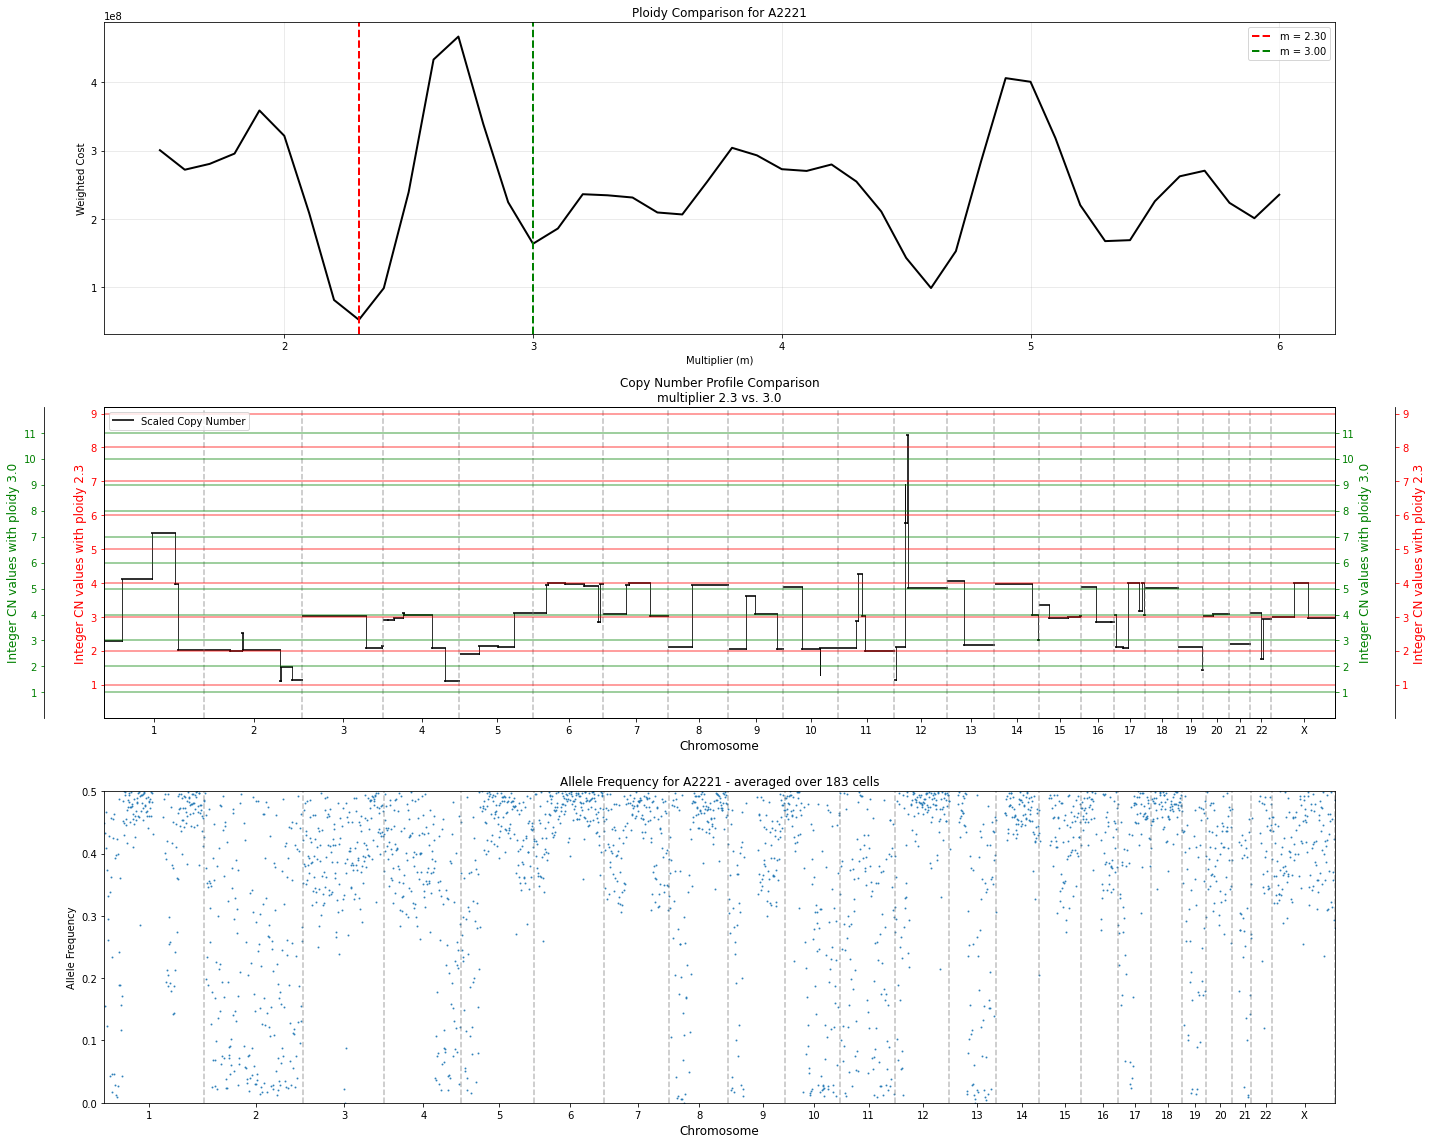

Compared 2.30 vs 3.00 for A2221

Creating ploidy comparison for population: A2222


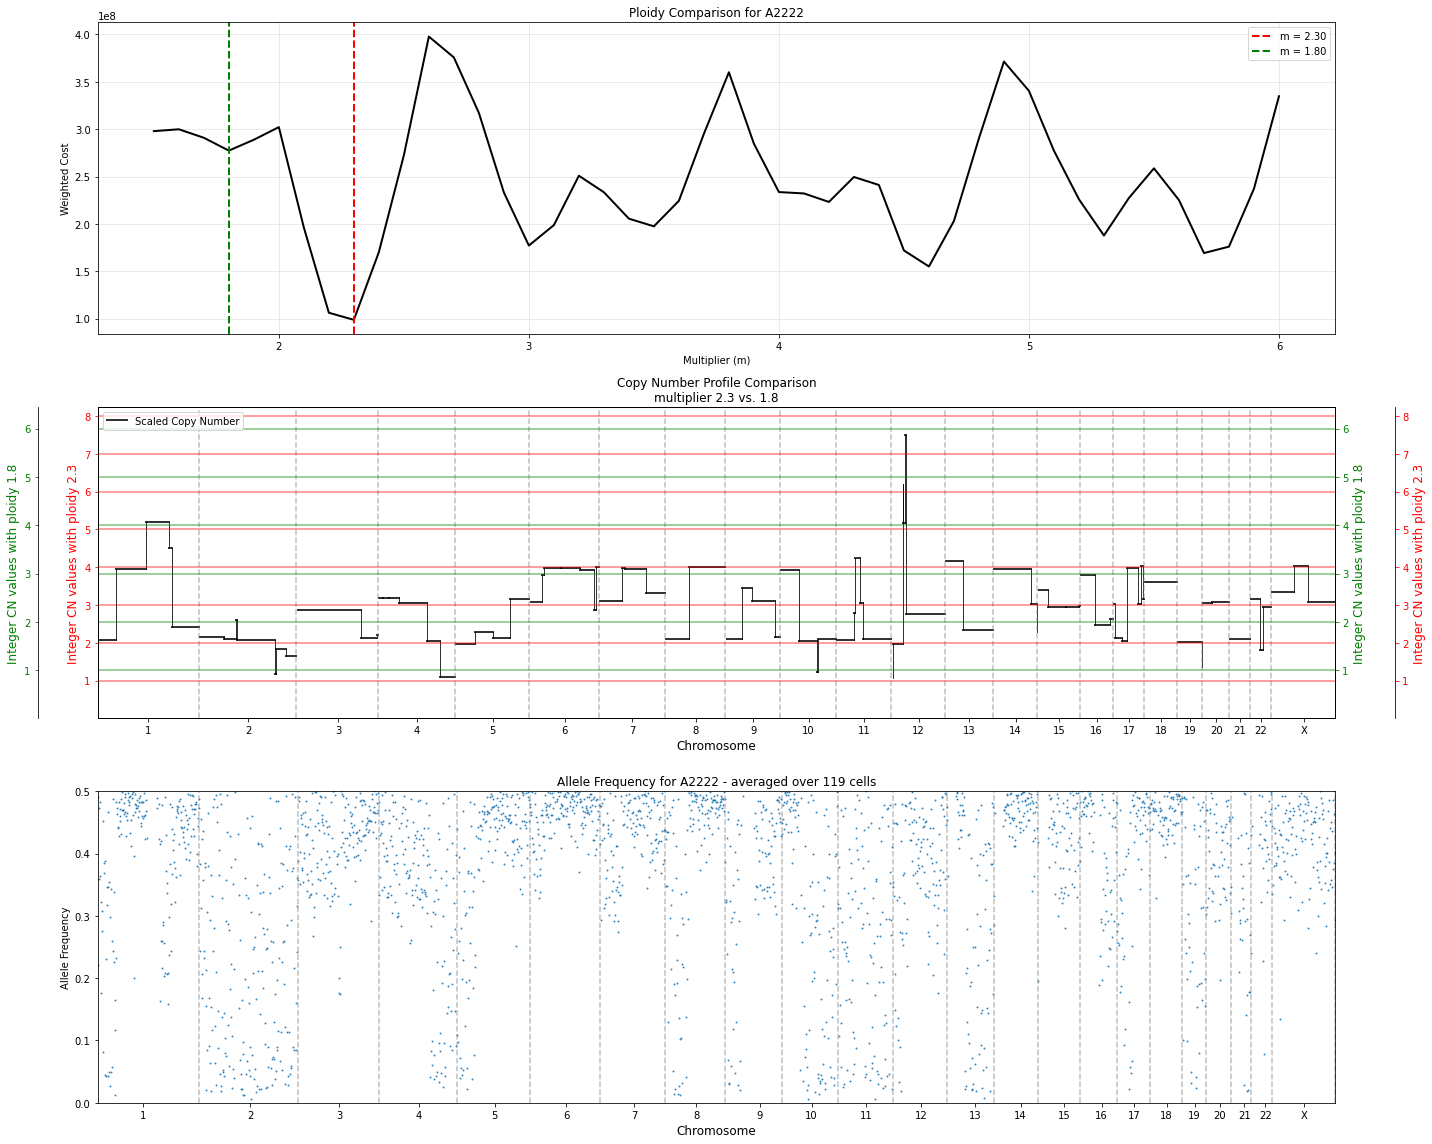

Compared 2.30 vs 1.80 for A2222


In [50]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - optimal_m) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [51]:
# # reorder A_dict based on new order from overlap_df index
# A_dict_reordered = {k: A_dict[k] for k in overlap_df.index}

In [52]:
# Add to your imports at the top:



In [53]:
# Create population summary table
summary_rows = []

for pop_name in A_dict.keys():
    # Get cells for this population
    pop_cells = A_dict[pop_name]['cells']
    num_cells = len(pop_cells)
    
        

    # Calculate average read count per cell for this population
    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells
    
    # Get relative counts (already computed in relative_counts_A)
    relative_count = relative_counts_A[pop_name].mean()

    if pop_name!= normal_A:
        results = ploidy_results_A[pop_name]
        local_minima = results['local_minima']
        target_m = 2 * relative_count
        #pick two best minima
        optimal_m = min(dict(local_minima).keys(), key=lambda x: abs(x - target_m))
        second_best_m = min([m for m, _ in local_minima if m != optimal_m], key=lambda x: abs(x - target_m))
    
    # Get relative ploidy from ploidy_results_A (if it exists, otherwise it's the normal so use 1.0)
    if pop_name in ploidy_results_A:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0  # Normal population
        second_best_m = 2.0
    
    # Add (normal) label if this is the normal population
    display_name = f"{pop_name} (normal)" if pop_name == normal_A else pop_name
    
    summary_rows.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_count,
        'best_ploidy': relative_ploidy,
        'second_best' : second_best_m
    })

# Create DataFrame
population_summary_table = pd.DataFrame(summary_rows)


#display it nicely
population_summary_table

,pop_name,num_cells,avg_read_count_per_cell,relative_counts,best_ploidy,second_best
0,A1 (normal),1725,59443.581449,1.000000,2.0,2.0
1,A21,369,69631.081301,1.171381,2.1,3.0
2,A2211,56,80295.321429,1.350782,2.7,3.5
3,A2212,81,72475.222222,1.219227,2.4,3.2
4,A2221,183,75329.765027,1.267248,2.3,3.0
5,A2222,119,74919.781513,1.260351,2.3,3.0


In [54]:
population_summary_table.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_A.txt", sep="\t", index=False)

=== Creating Copy Number Heatmaps ===
Processing 89 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap A matrix dimensions: 89 segments × 2533 cells
Expanding heatmap from 89 segments to 5431 rows...

Chromosome representation in heatmap:
chr1: 453 rows, 246,159,932 bp total
chr2: 434 rows, 235,824,599 bp total
chr3: 360 rows, 196,141,480 bp total
chr4: 339 rows, 183,819,298 bp total
chr5: 329 rows, 178,463,482 bp total
chr6: 307 rows, 166,930,960 bp total
chr7: 289 rows, 156,878,815 bp total
chr8: 268 rows, 145,153,934 bp total
chr9: 240 rows, 130,597,528 bp total
chr10: 244 rows, 132,750,269 bp total
chr11: 243 rows, 132,171,512 bp total
chr12: 234 rows, 127,192,322 bp total
chr13: 209 rows, 113,902,193 bp total
chr14: 194 rows, 105,604,444 bp total
chr15: 184 rows, 100,011,182 bp total
chr16: 142 rows, 77,331,877 bp total
chr17: 136 r

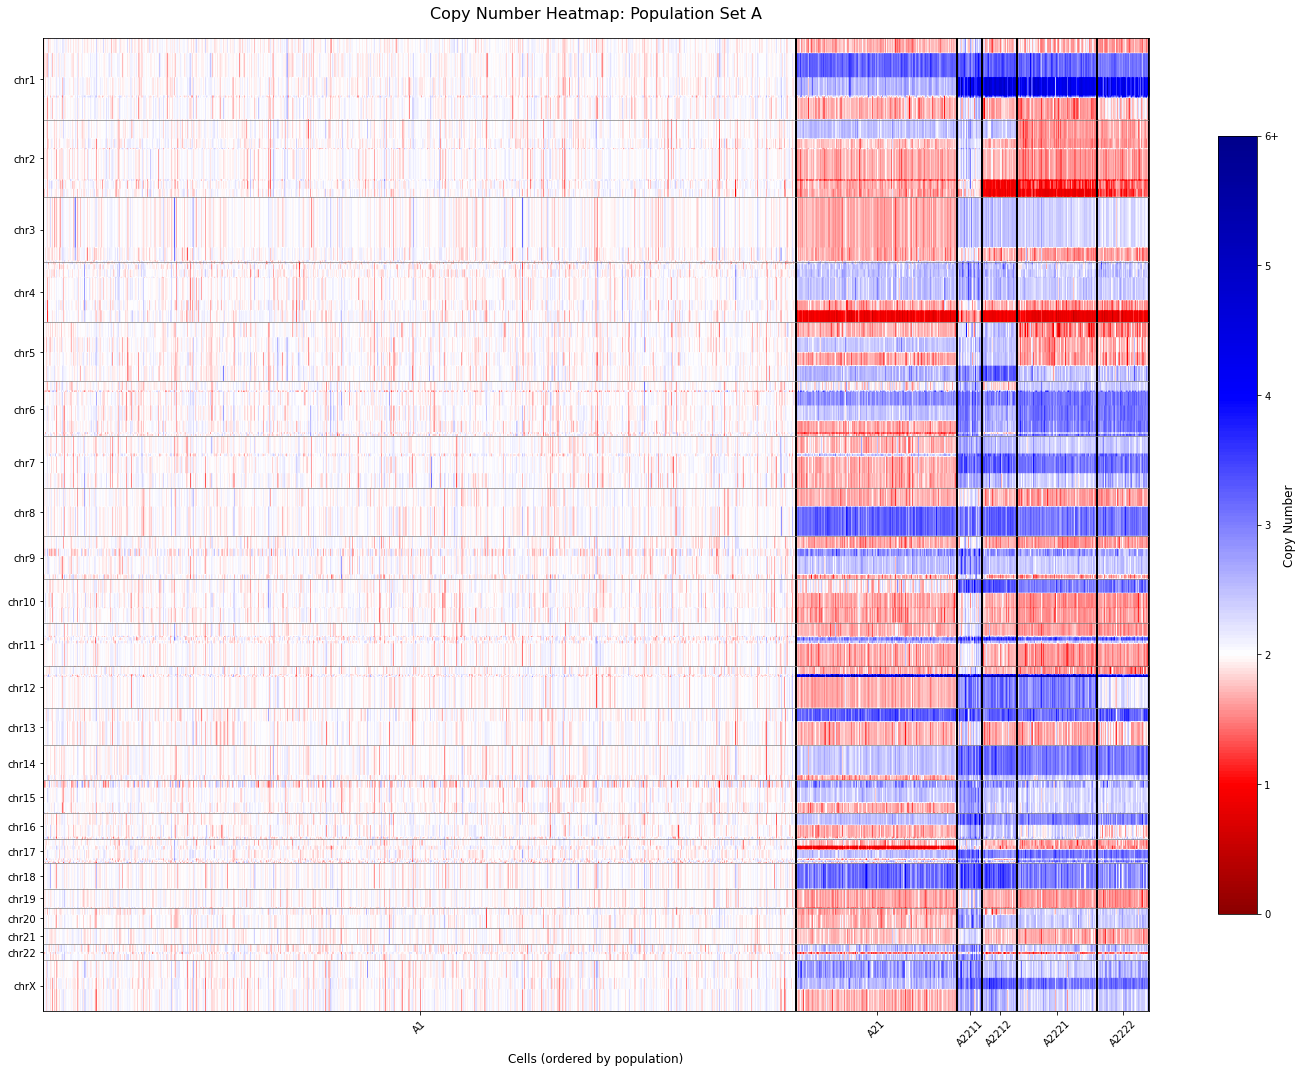

In [55]:
from copy_number import create_copy_number_matrix_fast
from visualization import plot_copy_number_heatmap, plot_overlap_matrix_figure

# Then you can use these functions in your analysis:

# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

KeyError: 'A1221'